
# 02 — Nonlinear Model Predictive Control (NMPC)

## Introduction and Objectives

This notebook develops and evaluates a **Nonlinear Model Predictive Control (NMPC)** controller for two-dimensional catheter navigation, providing a benchmark for comparison with Soft Actor-Critic (SAC) reinforcement learning.

The catheter simulation environment, including the S-shaped vessel geometry, blood-flow model, catheter dynamics, reward formulation and optional stochastic disturbances, has already been developed and validated in **`01_environment_development.ipynb`** and consolidated into reusable Python modules within `catheter_sim/`.

MPC predicts future system behaviour over a finite horizon, optimises a sequence of control actions to minimise a specified cost function, and applies the first action before repeating the optimisation at the next timestep.

### Experimental Plan

The experiments will be conducted in three stages:

1. **MPC Setup and Implementation** Implement the MPC prediction model, objective function, constraints and numerical optimiser using SciPy. Some reuseable functions (specifically for MPC but not required for SAC) have been coded into the mpc.py module within `catheter_sim/`. This set up and implementation stage will involve testing that these functions work as expected. 

2. **Baseline evaluation:** Develop and tune NMPC on the constant-width S-shaped vessel under nominal (baseline) physical parameters, with stochastic noise disabled. Evaluate navigation success, wall violations and completion time. This baseline environment will be refered to as G1 in this notebook

2. **Cost sensitivity and ablation:** Systematically vary the relative emphasis on navigation progress, wall proximity and control effort, and selectively remove objective terms to assess their contributions to performance. 

3. **Robustness and generalisation:** Evaluate the selected controller under unseen vessel stenosis, variations in physical parameters and stochastic disturbances. 



## MPC Setup and Implementation 

Implement the MPC prediction model, objective function, constraints and numerical optimiser using SciPy.

In [ ]:

# ======================================================================
# IMPORT THE REQUIRED PACKAGES AND MODULES
# ======================================================================

# Numerical calculations and plotting.
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

# SciPy numerical optimiser for the MPC control problem.
from scipy.optimize import minimize

# Timer for measuring MPC optimisation time.
from time import perf_counter

# Import configuration classes developed in the environment notebook.
from catheter_sim.config import (
    SVesselConfig,
    EnvironmentConfig,
    RewardConfig
)

# Import the S-shaped vessel class and constant-width profile.
from catheter_sim.geometry import SVessel, constant_width

# Import the Gymnasium catheter navigation environment.
from catheter_sim.environment import CatheterEnv

# Import our RK45-based catheter state integrator.
from catheter_sim.dynamics import integrate_catheter

# Import our shared episode evaluation and performance-summary functions.
from catheter_sim.evaluation import evaluate_episode, summarise_evaluations

# Import the trajectory predictor from the MPC module.
from catheter_sim.mpc import predict_trajectory, MPCCostConfig, calculate_mpc_cost,  optimise_control_sequence, MPCController

#Import the dataclass replace function for modifying cost MPC configurations without altering the original instance.
from dataclasses import replace

# Import the Path class for creating and managing output directories.
from pathlib import Path

# ======================================================================
# DEFINE THE NOMINAL CONSTANT-WIDTH S-SHAPED VESSEL (G1)
# ======================================================================

# Specify the two arcs making up the S-shaped centreline.
# Geometry dimensions are expressed in metres, and angles in radians.
vessel_config = SVesselConfig(
    arc_radius_1=0.03,           # Radius of the first circular arc (30 mm).
    arc_radius_2=0.03,           # Radius of the second circular arc (30 mm).
    arc_angle_1=np.pi / 2,       # First arc spans 90 degrees.
    arc_angle_2=np.pi / 2,       # Second arc spans 90 degrees.
    start_x=0.0,                 # Starting x-coordinate (m).
    start_y=0.0,                 # Starting y-coordinate (m).
    start_angle=0.0,             # Initial centreline direction (radians).
    num_points=500              # Discretisation points per circular arc.
)

# Construct G1 with a constant vessel radius of 3 mm.
# The target is placed 85% of the way along the centreline.
vessel = SVessel(
    config=vessel_config,
    width_profile=constant_width,
    radius=0.003,
    target_fraction=0.85
)


# ======================================================================
# DEFINE THE NOMINAL CATHETER ENVIRONMENT PARAMETERS
# ======================================================================

# Configure catheter dynamics, blood flow and episode termination.
# These values match our previous environment integration tests.
env_config = EnvironmentConfig(
    mass=0.001,                  # Effective catheter mass (kg).
    blood_density=1060.0,       # Blood density (kg/m^3).
    drag_coefficient=1.0,       # Dimensionless drag coefficient.
    reference_area=1e-6,        # Effective drag reference area (m^2).
    max_flow_speed=0.20,        # Maximum blood-flow speed (m/s).
    max_force=0.001,            # Maximum applied force per axis (N), provisional.
    dt=0.01,                    # Simulation time step (s).
    rtol=1e-6,                  # RK45 relative error tolerance.
    atol=1e-9,                  # RK45 absolute error tolerance.
    target_tolerance=0.002,     # Distance threshold for target success (2 mm).
    max_episode_steps=1000      # Maximum number of simulation steps.
)

# Environment reward parameters are needed by CatheterEnv.
# MPC will use its own optimisation cost function, defined later.
reward_config = RewardConfig(
    progress_weight=10.0,       # Reward weight for forward navigation progress.
    wall_weight=0.01,           # Penalty weight for proximity to vessel walls.
    control_weight=0.001,       # Penalty weight for control-force magnitude.
    success_bonus=10.0,         # Additional reward for reaching the target.
    failure_penalty=10.0        # Penalty for exiting the vessel.
)

# ======================================================================
# CREATE AND INITIALISE THE BASELINE ENVIRONMENT
# ======================================================================

# Construct the environment using G1 and nominal physical parameters.
# Disable process noise for initial MPC development and baseline tuning.
env = CatheterEnv(
    vessel=vessel,
    config=env_config,
    reward_config=reward_config,
    sigma_position=0.0,         # No random position disturbances.
    sigma_velocity=0.0          # No random velocity disturbances.
)

# Reset the environment to its initial catheter state.
# The seed makes the setup reproducible if randomness is introduced later.
observation, info = env.reset(seed=42)

# Display key settings to verify correct environment initialisation.
print("MPC baseline environment: INITIALISED")
print(f"Vessel length: {vessel.length * 1000:.2f} mm")
print(f"Vessel radius: {0.003 * 1000:.2f} mm")
print(f"Simulation timestep: {env_config.dt} s")
print(f"Maximum force per component: {env_config.max_force} N")
print(f"Initial catheter state: {env.state}")
print(f"Observation shape: {observation.shape}")


MPC baseline environment: INITIALISED
Vessel length: 94.25 mm
Vessel radius: 3.00 mm
Simulation timestep: 0.01 s
Maximum force per component: 0.001 N
Initial catheter state: [9.44364969e-05 1.48637901e-07 0.00000000e+00 0.00000000e+00]
Observation shape: (6,)


### Horizon function validation

First, we validate a function `predict_trajectory` which will take in a sequence of MPC control forces, apply those forces on a catheter sequentially, and output the trajectory (also called prediction horizon) taken by the catheter after applying these forces. This function will only be tested here (not defined) as it has already been defined within the in `catheter_sim/mpc.py` module. 

**Validaton objective:** Ensure that the trajectory being optimized internally by MPC is the same trajectory generated by the custom gym environment

In [2]:

# ======================================================================
# TEST MPC TRAJECTORY PREDICTION AGAINST THE EXISTING ENVIRONMENT
# ======================================================================

# Reset the environment to ensure a known initial state.
observation, info = env.reset(seed=42)

# Save the initial physical state [x, y, vx, vy].
initial_state = env.state.copy()

# Define five test control forces in Newtons.
# Each row is [Fx, Fy], and each component stays within ±0.001 N.
control_sequence = np.array([
    [0.0001,  0.0000],
    [0.0002,  0.0000],
    [0.0002,  0.0001],
    [0.0001, -0.0001],
    [0.0000,  0.0000]
], dtype=np.float32)

# ------------------------------------------------------------
# TEST 1 — PREDICT FUTURE STATES USING OUR MPC FUNCTION
# ------------------------------------------------------------

# Predict five future states using consecutive RK45 integrations.
predicted_trajectory = predict_trajectory(
    initial_state=initial_state,
    control_sequence=control_sequence,
    vessel=vessel,
    env_config=env_config
)

# Confirm that we obtained six states: initial + five future states.
assert predicted_trajectory.shape == (6, 4)

print("MPC trajectory prediction: PASSED")
print("Predicted trajectory shape:", predicted_trajectory.shape)


# ------------------------------------------------------------
# TEST 2 — SIMULATE THE SAME ACTIONS USING CATHETERENV
# ------------------------------------------------------------

# Store the initial state before advancing the environment.
actual_states = [env.state.copy()]

# Apply exactly the same forces to the deterministic environment.
for action in control_sequence:

    # Advance the actual environment by one simulation timestep.
    observation, reward, terminated, truncated, info = env.step(action)

    # Record the resulting physical state.
    actual_states.append(env.state.copy())

    # The test sequence should not terminate the episode prematurely.
    assert not terminated and not truncated

# Convert the recorded states into a NumPy array.
actual_trajectory = np.asarray(actual_states)

# ------------------------------------------------------------
# TEST 3 — COMPARE PREDICTED AND SIMULATED TRAJECTORIES
# ------------------------------------------------------------

# Calculate absolute differences for every state variable and timestep.
absolute_errors = np.abs(predicted_trajectory - actual_trajectory)

# Find the largest numerical difference across the complete trajectory.
max_absolute_error = np.max(absolute_errors)

# Check that the two trajectories agree to a tight numerical tolerance.
assert np.allclose(
    predicted_trajectory,
    actual_trajectory,
    rtol=1e-10,
    atol=1e-12
)

print("\nRK45 predictor vs CatheterEnv: PASSED")
print(f"Maximum absolute state error: {max_absolute_error:.3e}")

# Display the final predicted and simulated states.
print("\nFinal predicted state:", predicted_trajectory[-1])
print("Final simulated state:", actual_trajectory[-1])

print("\nMPC trajectory prediction validation: PASSED")


MPC trajectory prediction: PASSED
Predicted trajectory shape: (6, 4)

RK45 predictor vs CatheterEnv: PASSED
Maximum absolute state error: 0.000e+00

Final predicted state: [3.00216381e-04 1.02350128e-05 7.01694862e-03 4.50925444e-06]
Final simulated state: [3.00216381e-04 1.02350128e-05 7.01694862e-03 4.50925444e-06]

MPC trajectory prediction validation: PASSED



### MPC Cost Function Validation

Next, we test the MPC cost function implemented as `calculate_mpc_cost()` in `catheter_sim/mpc.py`.

The cost function follows the formulation proposed in the research proposal, with normalisation applied to the distance and control-force terms:

$$
J = \sum_{k=0}^{N-1}
\left[
w_p\left(\frac{d_k}{L}\right)^2
+ w_u\left\|\frac{\mathbf{u}_k}{F_{\max}}\right\|^2
+ w_w\phi(d_{\mathrm{wall},k})
\right]
+ w_T\left(\frac{d_N}{L}\right)^2
$$

where:

- $d_k$ is the remaining centreline distance to the target.
- $\mathbf{u}_k$ is the applied control force.
- $\phi(d_{\mathrm{wall},k})$ penalises proximity to and violation of vessel boundaries.
- $L$ and $F_{\max}$ normalise the distance and force terms.
- $w_p$, $w_u$, $w_w$ and $w_T$ are configurable cost weights.

The wall penalty uses a quadratic proximity penalty with an additional penalty for vessel-boundary violations.

**Validation objective:** Verify that the cost function behaves as intended: decreasing with navigation progress and increasing with control effort, wall proximity and boundary violations. The terminal cost should also decrease as the predicted endpoint approaches the target.


In [3]:

# ======================================================================
# TEST MPC COST FUNCTION — PROGRESS, CONTROL, WALL AND TERMINAL COSTS
# ======================================================================


# ======================================================================
# PREPARE TEST STATES AND CONTROL ACTIONS
# ======================================================================

# Select two centreline points, one farther from the target than the other.
far_index = int(0.15 * (len(vessel.centreline) - 1))
near_index = int(0.65 * (len(vessel.centreline) - 1))

# Construct physical states with zero velocity at each selected position.
far_state = np.array([*vessel.centreline[far_index], 0.0, 0.0])
near_state = np.array([*vessel.centreline[near_index], 0.0, 0.0])

# Define zero force and half-maximum force for comparison.
zero_force = np.zeros((1, 2))
half_force = np.array([[0.5 * env_config.max_force, 0.0]])

# Create the initial MPC cost configuration.
cost_config = MPCCostConfig(
    progress_weight=1.0,
    control_weight=0.01,
    wall_weight=10.0,
    terminal_weight=5.0,
    safety_margin_fraction=0.5,
    exit_penalty=100.0
)

# Small helper function: create a one-step trajectory with identical
# initial and final states, allowing controlled cost comparisons.
def stationary_trajectory(state):
    return np.stack([state, state])


# ======================================================================
# TEST 1 — NAVIGATION PROGRESS COST
# ======================================================================

# Isolate the running progress term by disabling all other weights.
progress_config = replace(
    cost_config,
    control_weight=0.0,
    wall_weight=0.0,
    terminal_weight=0.0
)

# Evaluate remaining-target cost at the two centreline positions.
far_progress_cost = calculate_mpc_cost(
    stationary_trajectory(far_state), zero_force,
    vessel, env_config, progress_config
)

near_progress_cost = calculate_mpc_cost(
    stationary_trajectory(near_state), zero_force,
    vessel, env_config, progress_config
)

# Being closer to the target should produce a lower progress cost.
assert near_progress_cost < far_progress_cost
print("Navigation progress cost: PASSED")
print(f"Far: {far_progress_cost:.6f} | Near: {near_progress_cost:.6f}")


# ======================================================================
# TEST 2 — CONTROL EFFORT COST
# ======================================================================

# Isolate the control-force penalty.
control_config = replace(
    cost_config,
    progress_weight=0.0,
    wall_weight=0.0,
    terminal_weight=0.0
)

# Compare zero force against a nonzero force for the same trajectory.
zero_control_cost = calculate_mpc_cost(
    stationary_trajectory(far_state), zero_force,
    vessel, env_config, control_config
)

half_control_cost = calculate_mpc_cost(
    stationary_trajectory(far_state), half_force,
    vessel, env_config, control_config
)

# Larger control-force magnitude must increase control cost.
assert np.isclose(zero_control_cost, 0.0)
assert half_control_cost > zero_control_cost
print("\nControl effort cost: PASSED")
print(f"Zero force: {zero_control_cost:.6f} | Half force: {half_control_cost:.6f}")


# ======================================================================
# TEST 3 — VESSEL-WALL PENALTY
# ======================================================================

# Isolate the wall penalty.
wall_config = replace(
    cost_config,
    progress_weight=0.0,
    control_weight=0.0,
    terminal_weight=0.0
)

# Use the far centreline point and calculate its local normal direction.
# The normal is perpendicular to the local centreline tangent.
tangent = vessel.centreline[far_index + 1] - vessel.centreline[far_index - 1]
tangent = tangent / np.linalg.norm(tangent)
normal = np.array([-tangent[1], tangent[0]])

# Use the same centreline location for three test positions.
# The first is at the centre, the second near the wall, and
# the third outside the vessel boundary.
centre_position = vessel.centreline[far_index]
local_radius = vessel.local_radius[far_index]

near_wall_position = centre_position + 0.9 * local_radius * normal
outside_position = centre_position + 1.2 * local_radius * normal

# Build zero-velocity states at these three positions.
centre_state = np.array([*centre_position, 0.0, 0.0])
wall_state = np.array([*near_wall_position, 0.0, 0.0])
outside_state = np.array([*outside_position, 0.0, 0.0])

# Confirm the signed-clearance convention before evaluating the cost.
assert vessel.wall_clearance(centre_position)[0] > 0.0
assert vessel.wall_clearance(near_wall_position)[0] > 0.0
assert vessel.wall_clearance(outside_position)[0] < 0.0

# Calculate the three wall penalties.
wall_costs = [
    calculate_mpc_cost(
        stationary_trajectory(state), zero_force,
        vessel, env_config, wall_config
    )
    for state in [centre_state, wall_state, outside_state]
]

# Wall cost should increase with proximity and boundary violation.
assert wall_costs[0] < wall_costs[1] < wall_costs[2]
print("\nWall penalty: PASSED")
print(f"Centre: {wall_costs[0]:.6f}")
print(f"Near wall: {wall_costs[1]:.6f}")
print(f"Outside vessel: {wall_costs[2]:.6f}")


# ======================================================================
# TEST 4 — TERMINAL TARGET COST
# ======================================================================

# Isolate the terminal cost.
terminal_config = replace(
    cost_config,
    progress_weight=0.0,
    control_weight=0.0,
    wall_weight=0.0
)

# Compare predicted endpoints at different distances from the target.
far_terminal_cost = calculate_mpc_cost(
    stationary_trajectory(far_state), zero_force,
    vessel, env_config, terminal_config
)

near_terminal_cost = calculate_mpc_cost(
    stationary_trajectory(near_state), zero_force,
    vessel, env_config, terminal_config
)

# A predicted endpoint closer to the target should have lower cost.
assert near_terminal_cost < far_terminal_cost
print("\nTerminal target cost: PASSED")
print(f"Far: {far_terminal_cost:.6f} | Near: {near_terminal_cost:.6f}")

print("\nMPC cost function validation: PASSED")


Navigation progress cost: PASSED
Far: 0.490561 | Near: 0.040160

Control effort cost: PASSED
Zero force: 0.000000 | Half force: 0.002500

Wall penalty: PASSED
Centre: 0.000000
Near wall: 6.400000
Outside vessel: 179.600000

Terminal target cost: PASSED
Far: 2.452806 | Near: 0.200802

MPC cost function validation: PASSED



### MPC Optimisation Validation

Next we test the `optimise_control_sequence()` function implemented in `catheter_sim/mpc.py`.

The function uses **SciPy's Sequential Least Squares Programming (SLSQP)** optimiser to minimise the MPC cost over a finite prediction horizon. Candidate control sequences are evaluated using the previously validated RK45 trajectory predictor and MPC cost function.

For this initial feasibility test, a prediction horizon of **5 steps (0.05 s)** is used, with control forces constrained to ±0.001 N per component.

The validation checks whether the optimiser:

1. Returns control forces within the specified limits.
2. Reduces the predicted MPC cost relative to an initial zero-force sequence.
3. Reports successful convergence and provides optimisation diagnostics.
4. Completes the optimisation within a measurable and practical computation time.


In [4]:

# ======================================================================
# TEST SCIPY MPC OPTIMISATION 
# ======================================================================

# Reset the environment to the same initial catheter state.
observation, info = env.reset(seed=42)
initial_state = env.state.copy()

# Retain the original optimisation settings for a fair comparison.
horizon = 5
maxiter = 50
ftol = 1e-5

# Begin with zero force over the five-step prediction horizon.
zero_sequence = np.zeros((horizon, 2), dtype=float)

# Calculate the reference cost using the updated MPC cost function.
zero_trajectory = predict_trajectory(
    initial_state, zero_sequence, vessel, env_config
)

initial_cost = calculate_mpc_cost(
    zero_trajectory, zero_sequence, vessel, env_config, cost_config
)

# Measure how long SciPy takes to solve the updated optimisation problem.
start_time = perf_counter()

optimal_sequence, result = optimise_control_sequence(
    initial_state=initial_state,
    vessel=vessel,
    env_config=env_config,
    cost_config=cost_config,
    horizon=horizon,
    initial_guess=zero_sequence,
    maxiter=maxiter,
    ftol=ftol
)

optimisation_time = perf_counter() - start_time

# Independently evaluate the control sequence returned by SciPy.
optimal_trajectory = predict_trajectory(
    initial_state, optimal_sequence, vessel, env_config
)

optimal_cost = calculate_mpc_cost(
    optimal_trajectory, optimal_sequence, vessel, env_config, cost_config
)

# Calculate the improvement relative to the zero-force reference.
cost_reduction = (
    100.0 * (initial_cost - optimal_cost) / abs(initial_cost)
    if abs(initial_cost) > 1e-12 else float("nan")
)

# Confirm that the returned forces remain within the permitted limits.
force_limits_satisfied = np.all(
    np.abs(optimal_sequence) <= env_config.max_force + 1e-12
)

# Display the optimisation results for comparison with the earlier test.
print("MPC OPTIMISATION — CONTINUOUS PROGRESS")
print("-" * 50)
print(f"Solver converged: {result.success}")
print(f"Solver message: {result.message}")
print(f"Iterations: {result.nit}")
print(f"Objective evaluations: {result.nfev}")
print(f"Optimisation time: {optimisation_time:.4f} s")

print(f"\nInitial zero-force cost: {initial_cost:.6f}")
print(f"Optimised cost: {optimal_cost:.6f}")
print(f"Cost reduction: {cost_reduction:.4f}%")
print(f"\nOptimal control sequence (N):\n{optimal_sequence}")
print(f"\nForce limits satisfied: {force_limits_satisfied}")

# Verify that the optimisation returned valid numerical results.
assert optimal_sequence.shape == (horizon, 2)
assert np.all(np.isfinite(optimal_sequence))
assert np.isfinite(optimal_cost)
assert force_limits_satisfied

print("\nUpdated MPC optimisation test: COMPLETED")

MPC OPTIMISATION — CONTINUOUS PROGRESS
--------------------------------------------------
Solver converged: True
Solver message: Optimization terminated successfully
Iterations: 13
Objective evaluations: 143
Optimisation time: 4.9934 s

Initial zero-force cost: 7.199924
Optimised cost: 7.104766
Cost reduction: 1.3217%

Optimal control sequence (N):
[[1.00000000e-03 9.42538224e-05]
 [1.00000000e-03 7.11997302e-05]
 [1.00000000e-03 4.88165448e-05]
 [7.10331031e-04 2.76467188e-05]
 [2.21731625e-04 8.46481926e-06]]

Force limits satisfied: True

Updated MPC optimisation test: COMPLETED



**Numerical implementation note:** This confirms that the SCIPY solver is able to optimize to optimize the MPC objective function (it reduced the cost by 1.3% in this case). Next, we will text this for longer environment interactions using closed loop MPC. 

**NB** MPC target-progress calculations use continuous projection onto centreline segments rather than the original nearest-sampled-point method. This improves the reliability of numerical gradient estimation. The simulation environment itself remains unchanged.



### Closed-Loop MPC Validation

Here we validate the `MPCController` class implemented in `catheter_sim/mpc.py` module.

Unlike the previous optimisation test, which calculated a control sequence only once, the controller now operates in **closed loop**. At each timestep, it optimises a sequence of future control forces, applies only the first force to `CatheterEnv`, and repeats the optimisation using the updated catheter state.

The controller also uses **warm-starting**, where the previous optimal control sequence is shifted forward to initialise the next optimisation.

#### Validation Procedure

An initial test of **five consecutive control steps** will be conducted on the deterministic, constant-width S-shaped vessel (G1).

The test will verify that:

1. The controller produces valid forces within the prescribed limits.
2. The catheter advances through the environment and makes navigation progress.
3. Warm-starting is applied between successive optimisations.
4. Solver convergence, iteration counts and computation times are recorded.

This short test assesses the operation and computational feasibility of closed-loop MPC. Complete navigation and systematic parameter tuning will be investigated subsequently.


In [5]:

# ======================================================================
# TEST CLOSED-LOOP MPC — FIVE CONSECUTIVE CONTROL STEPS
# ======================================================================

# Reset the environment to the initial catheter state.
observation, info = env.reset(seed=42)

# Create the MPC controller using the existing vessel and configurations.
mpc_controller = MPCController(
    vessel=vessel,
    env_config=env_config,
    cost_config=cost_config,
    horizon=5,                  # Predict five future control steps.
    maxiter=50,                 # Maximum SLSQP iterations per optimisation.
    ftol=1e-5                   # Solver convergence tolerance.
)

# Explicitly reset the controller's warm-start sequence and diagnostics.
mpc_controller.reset()

# Configure the short closed-loop test.
n_test_steps = 5

# Record the initial physical state and remaining target distance.
initial_state = env.state.copy()
initial_distance = vessel.distance_to_target(initial_state[:2])

# Store the trajectory and actions for inspection.
states = [initial_state.copy()]
actions = []

print("CLOSED-LOOP MPC VALIDATION")
print("-" * 85)
print(
    f"{'Step':<7}"
    f"{'Fx (mN)':>12}"
    f"{'Fy (mN)':>12}"
    f"{'Progress (mm)':>18}"
    f"{'Converged':>13}"
    f"{'Time (s)':>13}"
)
print("-" * 85)

# ======================================================================
# EXECUTE FIVE RECEDING-HORIZON CONTROL STEPS
# ======================================================================

for step in range(n_test_steps):

    # Preserve the current warm-start sequence before optimisation.
    # This lets us verify that the controller updates it correctly.
    previous_guess = mpc_controller.initial_guess.copy()

    # Optimise a five-step force sequence and select its first action.
    action = mpc_controller(observation)

    # Retrieve diagnostics from the optimisation just completed.
    diagnostics = mpc_controller.optimisation_history[-1]

    # Check that the returned action is finite and within force bounds.
    assert action.shape == (2,)
    assert np.all(np.isfinite(action))
    assert np.all(np.abs(action) <= env_config.max_force + 1e-12)

    # Apply the selected force to the actual catheter environment.
    observation, reward, terminated, truncated, info = env.step(action)

    # Record the new physical state and the force applied.
    states.append(env.state.copy())
    actions.append(action.copy())

    # Calculate cumulative navigation progress from the initial position.
    current_distance = vessel.distance_to_target(env.state[:2])
    progress_mm = (initial_distance - current_distance) * 1000.0

    # Display the action, progress and optimisation diagnostics.
    print(
        f"{step + 1:<7}"
        f"{action[0] * 1000:>12.6f}"
        f"{action[1] * 1000:>12.6f}"
        f"{progress_mm:>18.6f}"
        f"{str(diagnostics['success']):>13}"
        f"{diagnostics['optimisation_time']:>13.4f}"
    )

    # Verify that the stored warm-start sequence is correctly shaped.
    assert mpc_controller.initial_guess.shape == (5, 2)

    # Confirm the controller has recorded one diagnostic per action.
    assert len(mpc_controller.optimisation_history) == step + 1

    # Stop if the environment terminates or reaches its time limit.
    if terminated or truncated:
        print(f"\nEpisode ended early: {info['outcome']}")
        break

# ======================================================================
# SUMMARISE THE SHORT CLOSED-LOOP TEST
# ======================================================================

# Convert collected states and actions into NumPy arrays.
states = np.asarray(states)
actions = np.asarray(actions)

# Extract the computation times for each optimisation.
optimisation_times = np.array([
    record["optimisation_time"]
    for record in mpc_controller.optimisation_history
])

# Count successful solver terminations.
n_converged = sum(
    record["success"]
    for record in mpc_controller.optimisation_history
)

# Calculate the total progress achieved during this short test.
final_distance = vessel.distance_to_target(states[-1, :2])
total_progress_mm = (initial_distance - final_distance) * 1000.0

print("\nCLOSED-LOOP TEST SUMMARY")
print("-" * 45)
print(f"Control steps completed: {len(actions)}")
print(f"Solver convergences: {n_converged}/{len(actions)}")
print(f"Total progress: {total_progress_mm:.6f} mm")
print(f"Mean optimisation time: {np.mean(optimisation_times):.4f} s")
print(f"Maximum optimisation time: {np.max(optimisation_times):.4f} s")
print(f"Final catheter state: {states[-1]}")
print(f"Final outcome: {info['outcome']}")

# Confirm that the recorded trajectory and actions are consistent.
assert states.shape == (len(actions) + 1, 4)
assert actions.shape == (len(actions), 2)

print("\nFive-step closed-loop MPC test: COMPLETED")


CLOSED-LOOP MPC VALIDATION
-------------------------------------------------------------------------------------
Step        Fx (mN)     Fy (mN)     Progress (mm)    Converged     Time (s)
-------------------------------------------------------------------------------------
1          1.000000    0.094254          0.094437         True       4.8716
2          1.000000    0.141415          0.188873         True       2.5670
3          1.000000    0.190233          0.472183         True       2.0250
4          1.000000    0.254461          0.849930         True       1.7715
5          1.000000    0.323455          1.322113         True       1.7013

CLOSED-LOOP TEST SUMMARY
---------------------------------------------
Control steps completed: 5
Solver convergences: 5/5
Total progress: 1.322113 mm
Mean optimisation time: 2.5873 s
Maximum optimisation time: 4.8716 s
Final catheter state: [0.00136671 0.00019394 0.05081188 0.01003669]
Final outcome: ongoing

Five-step closed-loop MPC test: 

## Baseline evaluation 

Develop and tune NMPC on the constant-width S-shaped vessel under nominal (baseline) physical parameters, with stochastic noise disabled.

We will commence by extending the closed loop MPC test above up to 50 control steps. This lets us know if MPC under current settings can navigate the catheter successfully. The results from this will determine the next steps in the tuning process

In [6]:

# ======================================================================
# EXTENDED CLOSED-LOOP MPC TEST — UP TO 50 CONTROL STEPS
# ======================================================================

# Reset the environment and controller to begin a fresh navigation attempt.
observation, info = env.reset(seed=42)
mpc_controller.reset()

# Limit this development test to 50 control decisions.
# The environment itself retains its original 1000-step episode limit.
max_test_steps = 50

# Record the starting physical state and remaining target distance.
initial_state = env.state.copy()
initial_distance = vessel.distance_to_target(initial_state[:2])

# Initialise lists for storing trajectory, actions and progress.
states = [initial_state.copy()]
actions = []
progress_history = [0.0]

# Track the episode's termination status.
terminated = False
truncated = False

# Measure the total wall-clock time required for this test.
test_start_time = perf_counter()

# ======================================================================
# RUN MPC IN CLOSED LOOP
# ======================================================================

for step in range(max_test_steps):

    # Optimise future forces and obtain the next physical control action.
    action = mpc_controller(observation)

    # Apply the action using the existing RK45 simulation environment.
    observation, reward, terminated, truncated, info = env.step(action)

    # Record the resulting physical state and applied control force.
    states.append(env.state.copy())
    actions.append(action.copy())

    # Measure cumulative progress towards the target in millimetres.
    current_distance = vessel.distance_to_target(env.state[:2])
    progress_mm = (initial_distance - current_distance) * 1000.0
    progress_history.append(progress_mm)

    # Print a short update every ten steps, or when the episode ends.
    if (step + 1) % 10 == 0 or terminated or truncated:
        print(
            f"Step {step + 1:>3} | "
            f"Progress: {progress_mm:>8.3f} mm | "
            f"Solver converged: "
            f"{mpc_controller.optimisation_history[-1]['success']}"
        )

    # Stop early if the catheter reaches the target, exits the vessel,
    # or reaches the environment's actual episode time limit.
    if terminated or truncated:
        print(f"\nEpisode ended: {info['outcome']}")
        break

# Calculate the total computation time for the test.
total_runtime = perf_counter() - test_start_time

# Convert recorded results into NumPy arrays for analysis.
states = np.asarray(states)
actions = np.asarray(actions)
progress_history = np.asarray(progress_history)

# Extract solver diagnostics recorded by the controller.
solver_history = mpc_controller.optimisation_history

optimisation_times = np.array([
    record["optimisation_time"] for record in solver_history
])

converged_count = sum(record["success"] for record in solver_history)

# ======================================================================
# DISPLAY TEST SUMMARY
# ======================================================================

print("\n50-STEP MPC FEASIBILITY SUMMARY")
print("-" * 45)
print(f"Steps completed: {len(actions)}")
print(f"Navigation progress: {progress_history[-1]:.3f} mm")
print(f"Environment outcome: {info['outcome']}")
print(f"Solver convergences: {converged_count}/{len(solver_history)}")
print(f"Mean optimisation time: {np.mean(optimisation_times):.3f} s")
print(f"Total computation time: {total_runtime:.2f} s")
print(f"Final catheter position: {states[-1, :2]}")

# Distinguish an unfinished development test from actual termination.
if not (terminated or truncated):
    print(
        "\nDevelopment test stopped at 50 steps; "
        "the navigation episode remains unfinished."
    )

print("\nExtended closed-loop MPC test: COMPLETED")


Step  10 | Progress:    5.288 mm | Solver converged: True
Step  20 | Progress:   22.570 mm | Solver converged: True
Step  27 | Progress:   36.925 mm | Solver converged: True

Episode ended: side_wall_violation

50-STEP MPC FEASIBILITY SUMMARY
---------------------------------------------
Steps completed: 27
Navigation progress: 36.925 mm
Environment outcome: side_wall_violation
Solver convergences: 27/27
Mean optimisation time: 2.431 s
Total computation time: 65.86 s
Final catheter position: [0.03124666 0.0190426 ]

Extended closed-loop MPC test: COMPLETED


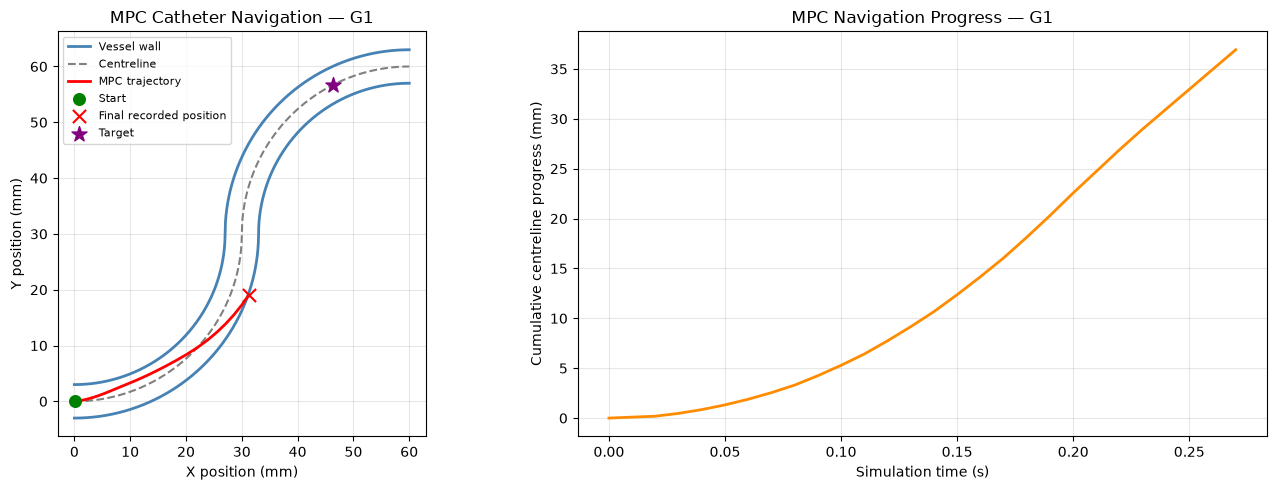

In [15]:

# ======================================================================
# VISUALISE MPC NAVIGATION — G1 FEASIBILITY TEST
# ======================================================================


# Extract catheter positions from the recorded states [x, y, vx, vy].
catheter_positions = states[:, :2]

# Convert all geometric coordinates from metres to millimetres.
centreline_mm = vessel.centreline * 1000.0
wall1_mm = vessel.wall1 * 1000.0
wall2_mm = vessel.wall2 * 1000.0
target_mm = vessel.target_position * 1000.0
catheter_positions_mm = catheter_positions * 1000.0

# Create a figure containing the navigation trajectory and progress.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ======================================================================
# PLOT 1 — CATHETER TRAJECTORY INSIDE THE VESSEL
# ======================================================================

# Plot the two physical vessel boundaries.
axes[0].plot(
    wall1_mm[:, 0], wall1_mm[:, 1],
    color="steelblue", linewidth=2, label="Vessel wall"
)
axes[0].plot(
    wall2_mm[:, 0], wall2_mm[:, 1],
    color="steelblue", linewidth=2
)

# Plot the vessel centreline.
axes[0].plot(
    centreline_mm[:, 0], centreline_mm[:, 1],
    color="gray", linestyle="--", linewidth=1.5,
    label="Centreline"
)

# Plot the actual MPC-controlled catheter trajectory.
axes[0].plot(
    catheter_positions_mm[:, 0],
    catheter_positions_mm[:, 1],
    color="red", linewidth=2,
    label="MPC trajectory"
)

# Mark the starting position, final recorded position and target.
axes[0].scatter(
    *catheter_positions_mm[0],
    color="green", marker="o", s=70,
    label="Start", zorder=5
)
axes[0].scatter(
    *catheter_positions_mm[-1],
    color="red", marker="x", s=90,
    label="Final recorded position", zorder=5
)
axes[0].scatter(
    *target_mm,
    color="purple", marker="*", s=130,
    label="Target", zorder=5
)

# Preserve the true proportions of the vessel geometry.
axes[0].set_aspect("equal", adjustable="box")
axes[0].set_xlabel("X position (mm)")
axes[0].set_ylabel("Y position (mm)")
axes[0].set_title("MPC Catheter Navigation — G1")
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3)

# ======================================================================
# PLOT 2 — CUMULATIVE NAVIGATION PROGRESS
# ======================================================================

# Convert recorded step indices into simulation time.
simulation_time = np.arange(len(progress_history)) * env_config.dt

# Plot the progress recorded during the closed-loop test.
axes[1].plot(
    simulation_time, progress_history,
    color="darkorange", linewidth=2
)

axes[1].set_xlabel("Simulation time (s)")
axes[1].set_ylabel("Cumulative centreline progress (mm)")
axes[1].set_title("MPC Navigation Progress — G1")
axes[1].grid(alpha=0.3)

# Display both plots.
plt.tight_layout()
plt.show()



### MPC Prediction Horizon Sensitivity — N = 10

The initial MPC test with a prediction horizon of 5 steps resulted in a side-wall violation after 27 control steps, despite successful solver convergence.

To investigate whether limited prediction time contributed to this failure, the horizon is increased from **5 to 10 steps** (0.05 s to 0.10 s), while keeping the cost weights and environment parameters unchanged.

The resulting trajectory, navigation outcome and computational time will be compared with the previous test to assess the effect of increasing the prediction horizon.


In [16]:

# ======================================================================
# MPC PREDICTION HORIZON TEST — N = 10
# ======================================================================

# Preserve results from the previous horizon-5 experiment.
# These will be useful for comparing trajectories and performance.
horizon5_results = {
    "states": states.copy(),
    "actions": actions.copy(),
    "progress_history": progress_history.copy(),
    "solver_history": [record.copy() for record in solver_history],
    "outcome": info["outcome"]
}

# Create a new MPC controller with a prediction horizon of 10 steps.
# All other controller settings remain unchanged.
mpc_controller_10 = MPCController(
    vessel=vessel,
    env_config=env_config,
    cost_config=cost_config,
    horizon=10,
    maxiter=50,
    ftol=1e-5
)

# Reset the environment using the same seed as the previous experiment.
observation, info = env.reset(seed=42)
mpc_controller_10.reset()

# Retain the same 50-step development-test cutoff.
max_test_steps = 50

# Record the initial catheter state and distance to the target.
initial_state = env.state.copy()
initial_distance = vessel.distance_to_target(initial_state[:2])

# Initialise storage for the new experiment.
states_10 = [initial_state.copy()]
actions_10 = []
progress_history_10 = [0.0]

terminated = False
truncated = False

# Start measuring total computation time.
test_start_time = perf_counter()

# ======================================================================
# RUN CLOSED-LOOP MPC WITH HORIZON = 10
# ======================================================================

for step in range(max_test_steps):

    # Optimise 10 future control forces and apply the first one.
    action = mpc_controller_10(observation)

    # Advance the physical environment using RK45.
    observation, reward, terminated, truncated, info = env.step(action)

    # Record the new state and applied force.
    states_10.append(env.state.copy())
    actions_10.append(action.copy())

    # Calculate cumulative navigation progress in millimetres.
    current_distance = vessel.distance_to_target(env.state[:2])
    progress_mm = (initial_distance - current_distance) * 1000.0
    progress_history_10.append(progress_mm)

    # Display progress every 10 steps or upon termination.
    if (step + 1) % 10 == 0 or terminated or truncated:
        print(
            f"Step {step + 1:>3} | "
            f"Progress: {progress_mm:>8.3f} mm | "
            f"Solver converged: "
            f"{mpc_controller_10.optimisation_history[-1]['success']}"
        )

    # Stop if the environment terminates or truncates the episode.
    if terminated or truncated:
        print(f"\nEpisode ended: {info['outcome']}")
        break

# Calculate total computation time.
total_runtime_10 = perf_counter() - test_start_time

# Convert recorded trajectories and actions into NumPy arrays.
states_10 = np.asarray(states_10)
actions_10 = np.asarray(actions_10)
progress_history_10 = np.asarray(progress_history_10)

# Retrieve the MPC solver diagnostics.
solver_history_10 = mpc_controller_10.optimisation_history

optimisation_times_10 = np.array([
    record["optimisation_time"] for record in solver_history_10
])

converged_count_10 = sum(
    record["success"] for record in solver_history_10
)

# Store the complete horizon-10 result for future comparisons.
horizon10_results = {
    "states": states_10.copy(),
    "actions": actions_10.copy(),
    "progress_history": progress_history_10.copy(),
    "solver_history": [record.copy() for record in solver_history_10],
    "outcome": info["outcome"],
    "runtime": total_runtime_10
}

# ======================================================================
# DISPLAY HORIZON-10 TEST SUMMARY
# ======================================================================

print("\nMPC HORIZON-10 FEASIBILITY SUMMARY")
print("-" * 45)
print(f"Steps completed: {len(actions_10)}")
print(f"Navigation progress: {progress_history_10[-1]:.3f} mm")
print(f"Environment outcome: {info['outcome']}")
print(f"Solver convergences: {converged_count_10}/{len(solver_history_10)}")
print(f"Mean optimisation time: {np.mean(optimisation_times_10):.3f} s")
print(f"Total computation time: {total_runtime_10:.2f} s")
print(f"Final catheter position: {states_10[-1, :2]}")

# Distinguish the development cutoff from actual episode termination.
if not (terminated or truncated):
    print(
        "\nDevelopment test stopped at 50 steps; "
        "the navigation episode remains unfinished."
    )

print("\nHorizon-10 MPC test: COMPLETED")


Step  10 | Progress:    5.288 mm | Solver converged: True
Step  20 | Progress:   22.004 mm | Solver converged: True
Step  30 | Progress:   42.308 mm | Solver converged: True
Step  40 | Progress:   65.350 mm | Solver converged: True
Step  47 | Progress:   78.477 mm | Solver converged: True

Episode ended: success

MPC HORIZON-10 FEASIBILITY SUMMARY
---------------------------------------------
Steps completed: 47
Navigation progress: 78.477 mm
Environment outcome: success
Solver convergences: 47/47
Mean optimisation time: 14.103 s
Total computation time: 663.20 s
Final catheter position: [0.0443088  0.05723146]

Horizon-10 MPC test: COMPLETED


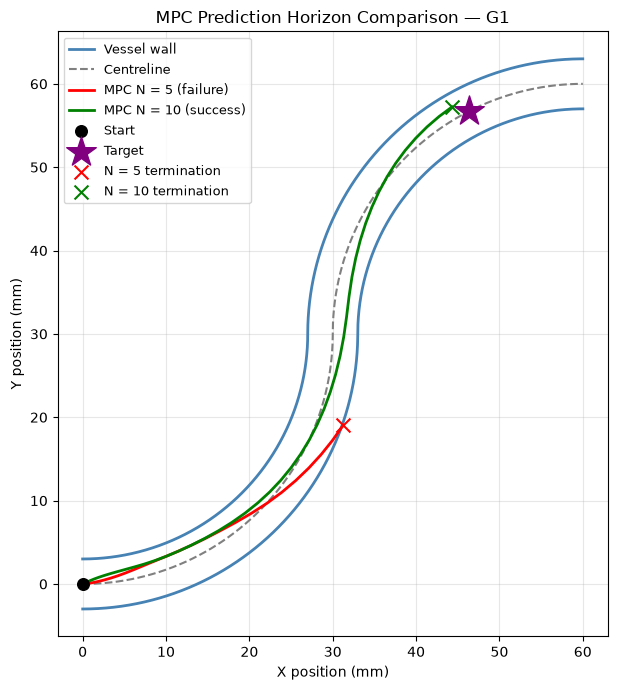

In [21]:

# ======================================================================
# VISUALISE MPC HORIZON COMPARISON — N = 5 VS N = 10
# ======================================================================

# Retrieve recorded catheter trajectories from both experiments.
states_5 = horizon5_results["states"]
states_10 = horizon10_results["states"]

# Convert vessel geometry from metres to millimetres.
centreline_mm = vessel.centreline * 1000.0
wall1_mm = vessel.wall1 * 1000.0
wall2_mm = vessel.wall2 * 1000.0
target_mm = vessel.target_position * 1000.0

# Extract catheter positions and convert to millimetres.
positions_5_mm = states_5[:, :2] * 1000.0
positions_10_mm = states_10[:, :2] * 1000.0

# Create a single figure for the trajectory comparison.
fig, ax = plt.subplots(figsize=(8, 7))

# Plot the vessel boundaries.
ax.plot(
    wall1_mm[:, 0], wall1_mm[:, 1],
    color="steelblue", linewidth=2, label="Vessel wall"
)
ax.plot(
    wall2_mm[:, 0], wall2_mm[:, 1],
    color="steelblue", linewidth=2
)

# Plot the vessel centreline.
ax.plot(
    centreline_mm[:, 0], centreline_mm[:, 1],
    color="gray", linestyle="--", linewidth=1.5,
    label="Centreline"
)

# Plot the horizon-5 trajectory (side-wall violation).
ax.plot(
    positions_5_mm[:, 0], positions_5_mm[:, 1],
    color="red", linewidth=2,
    label="MPC N = 5 (failure)"
)

# Plot the horizon-10 trajectory (successful navigation).
ax.plot(
    positions_10_mm[:, 0], positions_10_mm[:, 1],
    color="green", linewidth=2,
    label="MPC N = 10 (success)"
)

# Mark the common starting position.
ax.scatter(
    *positions_5_mm[0],
    color="black", marker="o", s=70,
    label="Start", zorder=5
)

# Mark the navigation target.
ax.scatter(
    *target_mm,
    color="purple", marker="*", s=500,
    label="Target", zorder=5
)

# Mark where the horizon-5 episode terminated.
ax.scatter(
    *positions_5_mm[-1],
    color="red", marker="x", s=100,
    label="N = 5 termination", zorder=5
)

# Mark where the horizon-10 episode terminated.
ax.scatter(
    *positions_10_mm[-1],
    color="green", marker="x", s=100,
    label="N = 10 termination", zorder=5
)

# Format the navigation plot.
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("X position (mm)")
ax.set_ylabel("Y position (mm)")
ax.set_title("MPC Prediction Horizon Comparison — G1")
ax.legend(fontsize=9)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()



### Preliminary MPC Results — Prediction Horizon Comparison

Closed-loop MPC was evaluated on the nominal S-shaped vessel (G1) using prediction horizons of 5 and 10 steps, with identical cost weights, physical parameters and solver settings.

| Metric | N = 5 | N = 10 |
|---|---|---|
| Navigation outcome | Side-wall violation | Success |
| Control steps | 27 | 47 |
| Navigation progress | 36.925 mm | 78.477 mm |
| Solver convergence | 27/27 | 47/47 |
| Mean optimisation time | 2.431 s | 14.103 s |
| Total computational runtime | 65.86 s | 663.20 s |

Increasing the prediction horizon from 5 to 10 steps enabled successful navigation through both vessel bends, suggesting that greater anticipation improves collision avoidance. However, mean optimisation time increased by approximately 5.8 times.

These preliminary results highlight a **trade-off between navigation performance and computational cost**. Further investigation will focus on trying to improve the computational efficiency.



### MPC Solver Efficiency Analysis

Following successful G1 navigation with a prediction horizon of 10 steps, the solver diagnostics are examined to assess computational efficiency.

The number of optimisation iterations, objective-function evaluations and solver execution times are analysed to determine whether the current SLSQP settings (`maxiter=50`, `ftol=1e-5`) warrant further tuning.

This analysis uses the previously recorded navigation results without rerunning the simulation.


MPC SOLVER EFFICIENCY — N = 10
--------------------------------------------------
Total control decisions: 47
Solver convergence rate: 100.0%

Iterations per optimisation:
  Mean: 12.45
  Minimum: 4
  Maximum: 29

Objective-function evaluations:
  Mean: 266.72
  Minimum: 88
  Maximum: 632

Optimisation time per control decision:
  Mean: 14.103 s
  Minimum: 4.224 s
  Maximum: 32.210 s

Optimisations reaching maxiter (50): 0


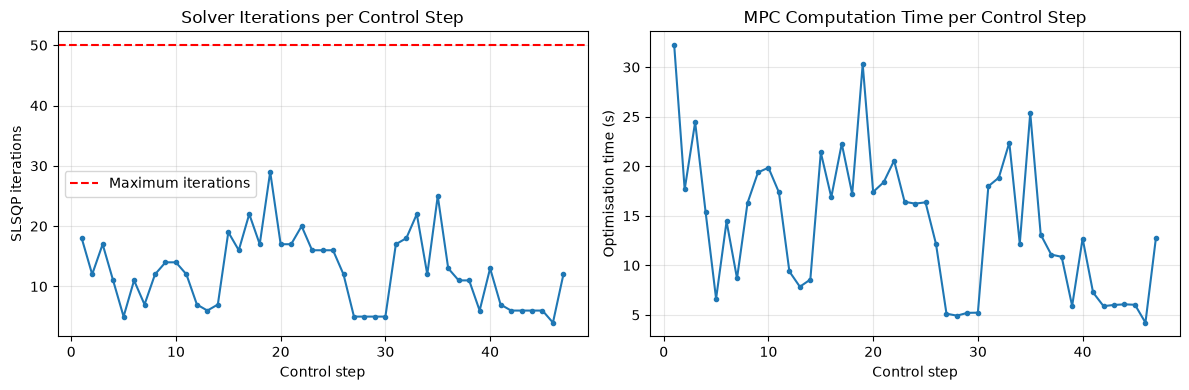

In [22]:

# ======================================================================
# ANALYSE MPC SOLVER PERFORMANCE — HORIZON = 10
# ======================================================================

# Retrieve diagnostics from the successful horizon-10 experiment.
solver_history_10 = horizon10_results["solver_history"]

# Extract iterations, function evaluations and optimisation times.
iterations = np.array([
    record["iterations"] for record in solver_history_10
])

function_evaluations = np.array([
    record["function_evaluations"] for record in solver_history_10
])

optimisation_times = np.array([
    record["optimisation_time"] for record in solver_history_10
])

# Extract solver convergence status at each control step.
convergence = np.array([
    record["success"] for record in solver_history_10
])

# Generate control-step numbers for plotting.
steps = np.arange(1, len(solver_history_10) + 1)

# ======================================================================
# PRINT SUMMARY STATISTICS
# ======================================================================

print("MPC SOLVER EFFICIENCY — N = 10")
print("-" * 50)

print(f"Total control decisions: {len(steps)}")
print(f"Solver convergence rate: {np.mean(convergence) * 100:.1f}%")

print(f"\nIterations per optimisation:")
print(f"  Mean: {np.mean(iterations):.2f}")
print(f"  Minimum: {np.min(iterations)}")
print(f"  Maximum: {np.max(iterations)}")

print(f"\nObjective-function evaluations:")
print(f"  Mean: {np.mean(function_evaluations):.2f}")
print(f"  Minimum: {np.min(function_evaluations)}")
print(f"  Maximum: {np.max(function_evaluations)}")

print(f"\nOptimisation time per control decision:")
print(f"  Mean: {np.mean(optimisation_times):.3f} s")
print(f"  Minimum: {np.min(optimisation_times):.3f} s")
print(f"  Maximum: {np.max(optimisation_times):.3f} s")

# Determine whether any optimisation reached the iteration limit.
maxiter = 50

print(
    f"\nOptimisations reaching maxiter ({maxiter}): "
    f"{np.sum(iterations >= maxiter)}"
)

# ======================================================================
# PLOT SOLVER ITERATIONS AND OPTIMISATION TIME
# ======================================================================

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Plot solver iterations for each MPC control decision.
axes[0].plot(
    steps, iterations,
    marker="o", markersize=3,
    linewidth=1.5
)
axes[0].axhline(
    maxiter, color="red", linestyle="--",
    label="Maximum iterations"
)
axes[0].set_xlabel("Control step")
axes[0].set_ylabel("SLSQP iterations")
axes[0].set_title("Solver Iterations per Control Step")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Plot computation time for each MPC control decision.
axes[1].plot(
    steps, optimisation_times,
    marker="o", markersize=3,
    linewidth=1.5
)
axes[1].set_xlabel("Control step")
axes[1].set_ylabel("Optimisation time (s)")
axes[1].set_title("MPC Computation Time per Control Step")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()



### MPC Solver Efficiency — Convergence Tolerance Sensitivity

From the analysis of the successful MPC configuration (`N=10`, `ftol=1e-5`) there was **100% solver convergence**, with an average of **12.45 iterations**, **266.72 objective-function evaluations**, and **14.103 seconds per control decision**. The maximum iteration count was 29, below the configured limit of 50, meaning that reducing `maxiter` would offer limited benefit.

To investigate whether computational efficiency can be improved without compromising navigation performance, the SLSQP convergence tolerance will be relaxed sequentially to **`ftol=1e-4`** and **`ftol=1e-3`**.

All other controller and environment parameters will remain unchanged. Navigation success, trajectory, solver convergence, objective-function evaluations and computation time will be compared against the original `ftol=1e-5` configuration.


In [26]:

# ======================================================================
# MPC CONVERGENCE TOLERANCE TEST — FTOL = 1e-4
# ======================================================================

# Create a new MPC controller with a relaxed convergence tolerance.
# Only ftol changes relative to the successful horizon-10 baseline.
mpc_controller_ftol4 = MPCController(
    vessel=vessel,
    env_config=env_config,
    cost_config=cost_config,
    horizon=10,
    maxiter=50,
    ftol=1e-4
)

# Reset the environment and the controller for an independent experiment.
observation, info = env.reset(seed=42)
mpc_controller_ftol4.reset()

# Keep the same 50-step development-test cutoff.
max_test_steps = 50

# Record the initial state and remaining distance to the target.
initial_state = env.state.copy()
initial_distance = vessel.distance_to_target(initial_state[:2])

# Initialise storage for the trajectory, actions and progress.
states_ftol4 = [initial_state.copy()]
actions_ftol4 = []
progress_ftol4 = [0.0]

terminated = False
truncated = False

# Start measuring the total wall-clock runtime.
test_start_time = perf_counter()

# ======================================================================
# RUN CLOSED-LOOP MPC
# ======================================================================

for step in range(max_test_steps):

    # Optimise the future force sequence and select the first action.
    action = mpc_controller_ftol4(observation)

    # Apply the action using the unchanged RK45 environment.
    observation, reward, terminated, truncated, info = env.step(action)

    # Record the resulting catheter state and applied force.
    states_ftol4.append(env.state.copy())
    actions_ftol4.append(action.copy())

    # Calculate cumulative navigation progress in millimetres.
    current_distance = vessel.distance_to_target(env.state[:2])
    progress_mm = (initial_distance - current_distance) * 1000.0
    progress_ftol4.append(progress_mm)

    # Display progress every ten steps or upon episode termination.
    if (step + 1) % 10 == 0 or terminated or truncated:
        print(
            f"Step {step + 1:>3} | "
            f"Progress: {progress_mm:>8.3f} mm | "
            f"Solver converged: "
            f"{mpc_controller_ftol4.optimisation_history[-1]['success']}"
        )

    # Stop if the environment reports success, failure or truncation.
    if terminated or truncated:
        print(f"\nEpisode ended: {info['outcome']}")
        break

# Calculate total computation time.
total_runtime_ftol4 = perf_counter() - test_start_time

# Convert recorded data to NumPy arrays.
states_ftol4 = np.asarray(states_ftol4)
actions_ftol4 = np.asarray(actions_ftol4)
progress_ftol4 = np.asarray(progress_ftol4)

# Retrieve the recorded solver diagnostics.
solver_history_ftol4 = mpc_controller_ftol4.optimisation_history

iterations_ftol4 = np.array([
    record["iterations"] for record in solver_history_ftol4
])

evaluations_ftol4 = np.array([
    record["function_evaluations"] for record in solver_history_ftol4
])

times_ftol4 = np.array([
    record["optimisation_time"] for record in solver_history_ftol4
])

converged_ftol4 = sum(
    record["success"] for record in solver_history_ftol4
)

# Store all results for later comparison with other tolerances.
ftol4_results = {
    "ftol": 1e-4,
    "states": states_ftol4.copy(),
    "actions": actions_ftol4.copy(),
    "progress_history": progress_ftol4.copy(),
    "solver_history": [record.copy() for record in solver_history_ftol4],
    "outcome": info["outcome"],
    "episode_finished": bool(terminated or truncated),
    "runtime": total_runtime_ftol4
}

# ======================================================================
# DISPLAY EXPERIMENT SUMMARY
# ======================================================================

print("\nMPC SOLVER TOLERANCE SUMMARY — FTOL = 1e-4")
print("-" * 50)
print(f"Steps completed: {len(actions_ftol4)}")
print(f"Navigation progress: {progress_ftol4[-1]:.3f} mm")
print(f"Environment outcome: {info['outcome']}")
print(f"Solver convergences: {converged_ftol4}/{len(solver_history_ftol4)}")
print(f"Mean solver iterations: {np.mean(iterations_ftol4):.2f}")
print(f"Mean objective evaluations: {np.mean(evaluations_ftol4):.2f}")
print(f"Mean optimisation time: {np.mean(times_ftol4):.3f} s")
print(f"Total computation time: {total_runtime_ftol4:.2f} s")

# A 50-step cutoff is not an environment termination.
if not (terminated or truncated):
    print("\nDevelopment test stopped at 50 steps; episode unfinished.")

print("\nFTOL = 1e-4 experiment: COMPLETED")


Step  10 | Progress:    5.383 mm | Solver converged: True
Step  20 | Progress:   22.004 mm | Solver converged: True
Step  30 | Progress:   42.119 mm | Solver converged: True
Step  40 | Progress:   65.350 mm | Solver converged: True
Step  47 | Progress:   79.043 mm | Solver converged: True

Episode ended: success

MPC SOLVER TOLERANCE SUMMARY — FTOL = 1e-4
--------------------------------------------------
Steps completed: 47
Navigation progress: 79.043 mm
Environment outcome: success
Solver convergences: 47/47
Mean solver iterations: 9.19
Mean objective evaluations: 197.26
Mean optimisation time: 6.639 s
Total computation time: 312.26 s

FTOL = 1e-4 experiment: COMPLETED


In [27]:

# ======================================================================
# MPC CONVERGENCE TOLERANCE TEST — FTOL = 1e-3
# ======================================================================

# Confirm that previous experiment results are still available.
# This prevents accidentally losing the comparison data.
assert "horizon10_results" in globals(), "Missing ftol=1e-5 results."
assert "ftol4_results" in globals(), "Missing ftol=1e-4 results."

# Create a new controller, changing only the convergence tolerance.
mpc_controller_ftol3 = MPCController(
    vessel=vessel,
    env_config=env_config,
    cost_config=cost_config,
    horizon=10,
    maxiter=50,
    ftol=1e-3
)

# Reset the same G1 environment to its initial state.
observation, info = env.reset(seed=42)
mpc_controller_ftol3.reset()

# Retain the same 50-step development-test cutoff.
max_test_steps = 50

# Record the initial catheter state and remaining target distance.
initial_state = env.state.copy()
initial_distance = vessel.distance_to_target(initial_state[:2])

# Initialise separate storage for the ftol=1e-3 experiment.
states_ftol3 = [initial_state.copy()]
actions_ftol3 = []
progress_ftol3 = [0.0]

terminated = False
truncated = False

# Begin measuring the total wall-clock computation time.
test_start_time = perf_counter()

# ======================================================================
# RUN CLOSED-LOOP MPC WITH FTOL = 1e-3
# ======================================================================

for step in range(max_test_steps):

    # Solve the MPC problem and select the first optimised force.
    action = mpc_controller_ftol3(observation)

    # Advance the catheter through the unchanged RK45 environment.
    observation, reward, terminated, truncated, info = env.step(action)

    # Record the catheter state and applied force separately.
    states_ftol3.append(env.state.copy())
    actions_ftol3.append(action.copy())

    # Calculate cumulative progress towards the target in millimetres.
    current_distance = vessel.distance_to_target(env.state[:2])
    progress_mm = (initial_distance - current_distance) * 1000.0
    progress_ftol3.append(progress_mm)

    # Display progress every 10 steps or upon episode termination.
    if (step + 1) % 10 == 0 or terminated or truncated:
        print(
            f"Step {step + 1:>3} | "
            f"Progress: {progress_mm:>8.3f} mm | "
            f"Solver converged: "
            f"{mpc_controller_ftol3.optimisation_history[-1]['success']}"
        )

    # Stop if the environment reports a terminal outcome.
    if terminated or truncated:
        print(f"\nEpisode ended: {info['outcome']}")
        break

# Calculate the total experiment runtime.
total_runtime_ftol3 = perf_counter() - test_start_time

# Convert the recorded trajectories and actions to NumPy arrays.
states_ftol3 = np.asarray(states_ftol3)
actions_ftol3 = np.asarray(actions_ftol3)
progress_ftol3 = np.asarray(progress_ftol3)

# Retrieve optimisation diagnostics from this controller only.
solver_history_ftol3 = mpc_controller_ftol3.optimisation_history

iterations_ftol3 = np.array([
    record["iterations"] for record in solver_history_ftol3
])

evaluations_ftol3 = np.array([
    record["function_evaluations"] for record in solver_history_ftol3
])

times_ftol3 = np.array([
    record["optimisation_time"] for record in solver_history_ftol3
])

converged_ftol3 = sum(
    record["success"] for record in solver_history_ftol3
)

# Save the experiment's results in a separate dictionary.
ftol3_results = {
    "ftol": 1e-3,
    "states": states_ftol3.copy(),
    "actions": actions_ftol3.copy(),
    "progress_history": progress_ftol3.copy(),
    "solver_history": [record.copy() for record in solver_history_ftol3],
    "outcome": info["outcome"],
    "episode_finished": bool(terminated or truncated),
    "runtime": total_runtime_ftol3
}

# ======================================================================
# DISPLAY EXPERIMENT SUMMARY
# ======================================================================

print("\nMPC SOLVER TOLERANCE SUMMARY — FTOL = 1e-3")
print("-" * 50)
print(f"Steps completed: {len(actions_ftol3)}")
print(f"Navigation progress: {progress_ftol3[-1]:.3f} mm")
print(f"Environment outcome: {info['outcome']}")
print(f"Solver convergences: {converged_ftol3}/{len(solver_history_ftol3)}")
print(f"Mean solver iterations: {np.mean(iterations_ftol3):.2f}")
print(f"Mean objective evaluations: {np.mean(evaluations_ftol3):.2f}")
print(f"Mean optimisation time: {np.mean(times_ftol3):.3f} s")
print(f"Total computation time: {total_runtime_ftol3:.2f} s")

# Distinguish a development cutoff from actual episode termination.
if not (terminated or truncated):
    print("\nDevelopment test stopped at 50 steps; episode unfinished.")

print("\nFTOL = 1e-3 experiment: COMPLETED")


Step  10 | Progress:    5.383 mm | Solver converged: True
Step  20 | Progress:   21.815 mm | Solver converged: True
Step  30 | Progress:   42.024 mm | Solver converged: True
Step  40 | Progress:   65.539 mm | Solver converged: True
Step  47 | Progress:   79.610 mm | Solver converged: True

Episode ended: success

MPC SOLVER TOLERANCE SUMMARY — FTOL = 1e-3
--------------------------------------------------
Steps completed: 47
Navigation progress: 79.610 mm
Environment outcome: success
Solver convergences: 47/47
Mean solver iterations: 6.28
Mean objective evaluations: 134.81
Mean optimisation time: 4.510 s
Total computation time: 212.17 s

FTOL = 1e-3 experiment: COMPLETED



Given the successful navigation and reduced computational cost observed at `ftol=1e-3`, an additional experiment with `ftol=1e-2` will investigate whether further relaxation improves solver efficiency without compromising navigation performance.

In [28]:

# ======================================================================
# MPC CONVERGENCE TOLERANCE TEST — FTOL = 1e-2
# ======================================================================

# Confirm that results from the previous tolerance experiments are available.
assert "horizon10_results" in globals(), "Missing ftol=1e-5 results."
assert "ftol4_results" in globals(), "Missing ftol=1e-4 results."
assert "ftol3_results" in globals(), "Missing ftol=1e-3 results."

# Create a new controller, changing only the convergence tolerance.
mpc_controller_ftol2 = MPCController(
    vessel=vessel,
    env_config=env_config,
    cost_config=cost_config,
    horizon=10,
    maxiter=50,
    ftol=1e-2
)

# Reset the same G1 environment and clear the controller's history.
observation, info = env.reset(seed=42)
mpc_controller_ftol2.reset()

# Keep the same 50-step development cutoff.
max_test_steps = 50

# Record the initial catheter state and remaining target distance.
initial_state = env.state.copy()
initial_distance = vessel.distance_to_target(initial_state[:2])

# Use separate variables to avoid overwriting previous experiments.
states_ftol2 = [initial_state.copy()]
actions_ftol2 = []
progress_ftol2 = [0.0]

terminated = False
truncated = False

# Start measuring total wall-clock computation time.
test_start_time = perf_counter()

# ======================================================================
# RUN CLOSED-LOOP MPC WITH FTOL = 1e-2
# ======================================================================

for step in range(max_test_steps):

    # Optimise the future control forces and select the first action.
    action = mpc_controller_ftol2(observation)

    # Apply the force using the unchanged RK45 simulation environment.
    observation, reward, terminated, truncated, info = env.step(action)

    # Record the resulting physical state and applied force.
    states_ftol2.append(env.state.copy())
    actions_ftol2.append(action.copy())

    # Calculate cumulative navigation progress in millimetres.
    current_distance = vessel.distance_to_target(env.state[:2])
    progress_mm = (initial_distance - current_distance) * 1000.0
    progress_ftol2.append(progress_mm)

    # Display an update every ten steps or at episode termination.
    if (step + 1) % 10 == 0 or terminated or truncated:
        print(
            f"Step {step + 1:>3} | "
            f"Progress: {progress_mm:>8.3f} mm | "
            f"Solver converged: "
            f"{mpc_controller_ftol2.optimisation_history[-1]['success']}"
        )

    # Stop if the environment reports success, failure or truncation.
    if terminated or truncated:
        print(f"\nEpisode ended: {info['outcome']}")
        break

# Calculate the experiment's total computation time.
total_runtime_ftol2 = perf_counter() - test_start_time

# Convert the recorded trajectory, actions and progress to NumPy arrays.
states_ftol2 = np.asarray(states_ftol2)
actions_ftol2 = np.asarray(actions_ftol2)
progress_ftol2 = np.asarray(progress_ftol2)

# Retrieve optimisation diagnostics from this controller only.
solver_history_ftol2 = mpc_controller_ftol2.optimisation_history

iterations_ftol2 = np.array([
    record["iterations"] for record in solver_history_ftol2
])

evaluations_ftol2 = np.array([
    record["function_evaluations"] for record in solver_history_ftol2
])

times_ftol2 = np.array([
    record["optimisation_time"] for record in solver_history_ftol2
])

converged_ftol2 = sum(
    record["success"] for record in solver_history_ftol2
)

# Store all results separately for the four-way comparison.
ftol2_results = {
    "ftol": 1e-2,
    "states": states_ftol2.copy(),
    "actions": actions_ftol2.copy(),
    "progress_history": progress_ftol2.copy(),
    "solver_history": [record.copy() for record in solver_history_ftol2],
    "outcome": info["outcome"],
    "episode_finished": bool(terminated or truncated),
    "runtime": total_runtime_ftol2
}

# ======================================================================
# DISPLAY EXPERIMENT SUMMARY
# ======================================================================

print("\nMPC SOLVER TOLERANCE SUMMARY — FTOL = 1e-2")
print("-" * 50)
print(f"Steps completed: {len(actions_ftol2)}")
print(f"Navigation progress: {progress_ftol2[-1]:.3f} mm")
print(f"Environment outcome: {info['outcome']}")
print(f"Solver convergences: {converged_ftol2}/{len(solver_history_ftol2)}")
print(f"Mean solver iterations: {np.mean(iterations_ftol2):.2f}")
print(f"Mean objective evaluations: {np.mean(evaluations_ftol2):.2f}")
print(f"Mean optimisation time: {np.mean(times_ftol2):.3f} s")
print(f"Total computation time: {total_runtime_ftol2:.2f} s")

# Distinguish the development cutoff from actual episode termination.
if not (terminated or truncated):
    print("\nDevelopment test stopped at 50 steps; episode unfinished.")

print("\nFTOL = 1e-2 experiment: COMPLETED")


Step  10 | Progress:    5.288 mm | Solver converged: True
Step  20 | Progress:   21.626 mm | Solver converged: True
Step  30 | Progress:   41.080 mm | Solver converged: True
Step  40 | Progress:   60.723 mm | Solver converged: True
Step  50 | Progress:   78.571 mm | Solver converged: True

Episode ended: success

MPC SOLVER TOLERANCE SUMMARY — FTOL = 1e-2
--------------------------------------------------
Steps completed: 50
Navigation progress: 78.571 mm
Environment outcome: success
Solver convergences: 50/50
Mean solver iterations: 2.06
Mean objective evaluations: 43.94
Mean optimisation time: 1.642 s
Total computation time: 82.35 s

FTOL = 1e-2 experiment: COMPLETED


In [ ]:

# ======================================================================
# COMPARE MPC SOLVER TOLERANCES — FTOL = 1e-5 TO 1e-2
# ======================================================================

# Retrieve the four previously completed MPC experiments.
# Each dictionary contains its own trajectory and solver diagnostics.
tolerance_results = {
    "1e-5": horizon10_results,
    "1e-4": ftol4_results,
    "1e-3": ftol3_results,
    "1e-2": ftol2_results
}

# Initialise a list to hold one summary row per experiment.
summary_rows = []

# ======================================================================
# CALCULATE PERFORMANCE METRICS FOR EACH TOLERANCE
# ======================================================================

for tolerance, result in tolerance_results.items():

    # Extract the recorded catheter states and applied actions.
    states_trial = result["states"]
    actions_trial = result["actions"]

    # Retrieve the optimiser's diagnostic records.
    solver_records = result["solver_history"]

    # Extract solver iterations, objective evaluations and computation time.
    iterations_trial = np.array([
        record["iterations"] for record in solver_records
    ])

    evaluations_trial = np.array([
        record["function_evaluations"] for record in solver_records
    ])

    optimisation_times_trial = np.array([
        record["optimisation_time"] for record in solver_records
    ])

    # Calculate the percentage of successful solver terminations.
    convergence_rate = 100.0 * np.mean([
        record["success"] for record in solver_records
    ])

    # Calculate cumulative navigation progress in millimetres.
    navigation_progress = result["progress_history"][-1]

    # Calculate simulated navigation time from the number of actions.
    simulation_time = len(actions_trial) * env_config.dt

    # Use recorded wall-clock runtime when available.
    # The original 1e-5 experiment did not store runtime in its dictionary.
    if "runtime" in result:
        total_runtime = result["runtime"]
    else:
        total_runtime = np.sum(optimisation_times_trial)

    # Add the current experiment's metrics to the summary.
    summary_rows.append({
        "ftol": tolerance,
        "Outcome": result["outcome"],
        "Control steps": len(actions_trial),
        "Progress (mm)": navigation_progress,
        "Simulation time (s)": simulation_time,
        "Convergence (%)": convergence_rate,
        "Mean iterations": np.mean(iterations_trial),
        "Mean evaluations": np.mean(evaluations_trial),
        "Total evaluations": np.sum(evaluations_trial),
        "Mean optimisation (s)": np.mean(optimisation_times_trial),
        "Total runtime (s)": total_runtime
    })

# ======================================================================
# CREATE AND DISPLAY THE COMPARISON TABLE
# ======================================================================

# Construct the results table and use tolerance values as row labels.
mpc_tolerance_summary = pd.DataFrame(summary_rows).set_index("ftol")

# Round numerical values for a readable notebook output.
display(mpc_tolerance_summary.round(3))

print("\nMPC convergence tolerance comparison: COMPLETED")


,Outcome,Control steps,Progress (mm),Simulation time (s),Convergence (%),Mean iterations,Mean evaluations,Total evaluations,Mean optimisation (s),Total runtime (s)
ftol,,,,,,,,,,
1e-5,success,47,78.477,0.47,100.0,12.447,266.723,12536,14.103,663.197
1e-4,success,47,79.043,0.47,100.0,9.191,197.255,9271,6.639,312.256
1e-3,success,47,79.610,0.47,100.0,6.277,134.809,6336,4.510,212.174
1e-2,success,50,78.571,0.50,100.0,2.060,43.940,2197,1.642,82.352



MPC convergence tolerance comparison: COMPLETED


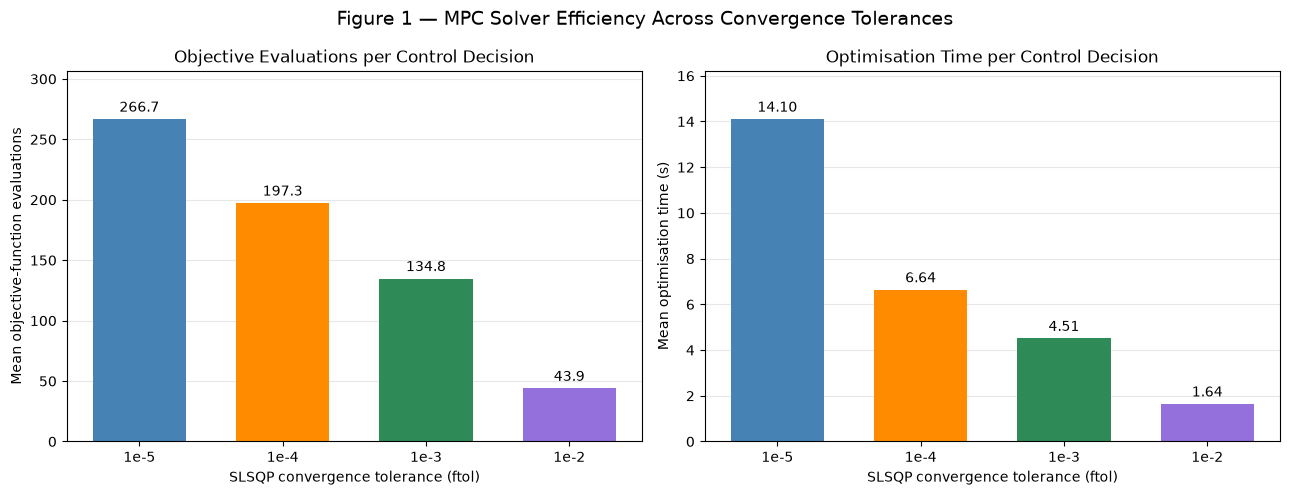

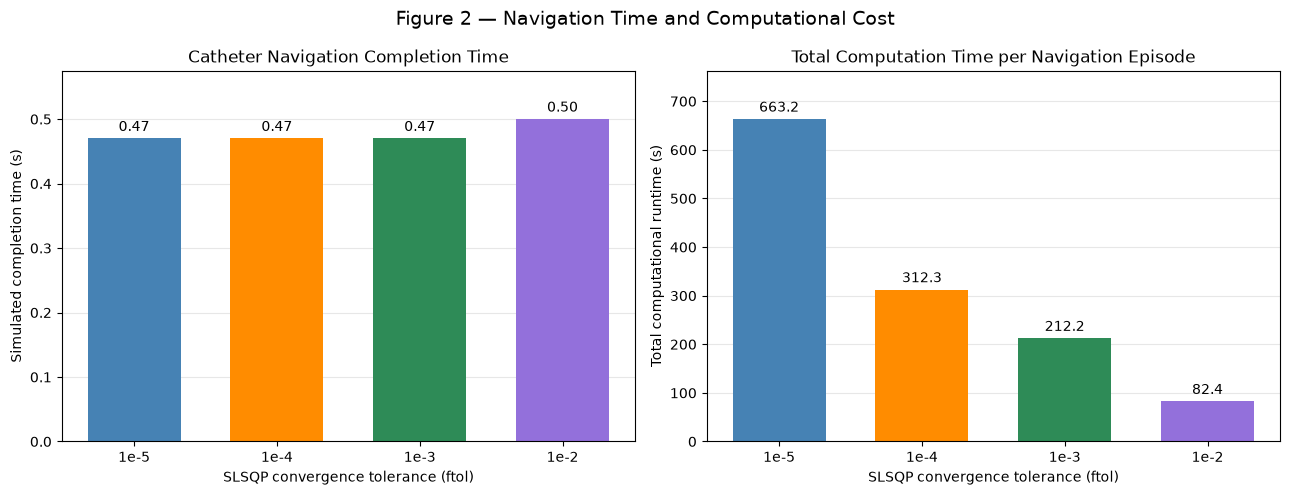

In [ ]:

# ======================================================================
# MPC CONVERGENCE TOLERANCE — COMPUTATIONAL PERFORMANCE COMPARISON
# ======================================================================

# Retrieve the tolerance labels and corresponding numerical results.
tolerances = mpc_tolerance_summary.index.tolist()
x = np.arange(len(tolerances))

# Extract performance metrics from the existing summary table.
mean_evaluations = mpc_tolerance_summary["Mean evaluations"].to_numpy()
mean_optimisation = mpc_tolerance_summary["Mean optimisation (s)"].to_numpy()
simulation_times = mpc_tolerance_summary["Simulation time (s)"].to_numpy()
total_runtimes = mpc_tolerance_summary["Total runtime (s)"].to_numpy()

# Use consistent colours across all four comparisons.
bar_colors = ["steelblue", "darkorange", "seagreen", "mediumpurple"]


# ======================================================================
# FIGURE 1 — SOLVER COMPUTATIONAL EFFICIENCY
# ======================================================================

fig2, axes2 = plt.subplots(1, 2, figsize=(13, 5))

# Plot mean objective-function evaluations per control decision.
bars = axes2[0].bar(
    x, mean_evaluations,
    color=bar_colors, width=0.65
)

axes2[0].set_xticks(x, tolerances)
axes2[0].set_xlabel("SLSQP convergence tolerance (ftol)")
axes2[0].set_ylabel("Mean objective-function evaluations")
axes2[0].set_title("Objective Evaluations per Control Decision")
axes2[0].grid(axis="y", alpha=0.3)
axes2[0].set_axisbelow(True)

# Display the numerical value above each bar.
axes2[0].bar_label(bars, fmt="%.1f", padding=3)

# Plot mean optimisation time per control decision.
bars = axes2[1].bar(
    x, mean_optimisation,
    color=bar_colors, width=0.65
)

axes2[1].set_xticks(x, tolerances)
axes2[1].set_xlabel("SLSQP convergence tolerance (ftol)")
axes2[1].set_ylabel("Mean optimisation time (s)")
axes2[1].set_title("Optimisation Time per Control Decision")
axes2[1].grid(axis="y", alpha=0.3)
axes2[1].set_axisbelow(True)

# Display optimisation time above each bar.
axes2[1].bar_label(bars, fmt="%.2f", padding=3)

fig2.suptitle(
    "Figure 1 — MPC Solver Efficiency Across Convergence Tolerances",
    fontsize=14
)

# Add 15% headroom so the value labels do not touch the top border.
axes2[0].set_ylim(0, np.max(mean_evaluations) * 1.15)
axes2[1].set_ylim(0, np.max(mean_optimisation) * 1.15)

fig2.tight_layout()
plt.show()


# ======================================================================
# FIGURE 2 — SIMULATED NAVIGATION TIME VS COMPUTATIONAL RUNTIME
# ======================================================================

fig3, axes3 = plt.subplots(1, 2, figsize=(13, 5))

# Plot simulated catheter navigation completion time.
bars = axes3[0].bar(
    x, simulation_times,
    color=bar_colors, width=0.65
)

axes3[0].set_xticks(x, tolerances)
axes3[0].set_xlabel("SLSQP convergence tolerance (ftol)")
axes3[0].set_ylabel("Simulated completion time (s)")
axes3[0].set_title("Catheter Navigation Completion Time")
axes3[0].grid(axis="y", alpha=0.3)
axes3[0].set_axisbelow(True)

# Display completion times above each bar.
axes3[0].bar_label(bars, fmt="%.2f", padding=3)

# Plot total computational runtime for each navigation episode.
bars = axes3[1].bar(
    x, total_runtimes,
    color=bar_colors, width=0.65
)

axes3[1].set_xticks(x, tolerances)
axes3[1].set_xlabel("SLSQP convergence tolerance (ftol)")
axes3[1].set_ylabel("Total computational runtime (s)")
axes3[1].set_title("Total Computation Time per Navigation Episode")
axes3[1].grid(axis="y", alpha=0.3)
axes3[1].set_axisbelow(True)

# Display total runtime above each bar.
axes3[1].bar_label(bars, fmt="%.1f", padding=3)

fig3.suptitle(
    "Figure 2 — Navigation Time and Computational Cost",
    fontsize=14
)

# Add 15% headroom above the tallest bars in both subplots.
axes3[0].set_ylim(0, np.max(simulation_times) * 1.15)
axes3[1].set_ylim(0, np.max(total_runtimes) * 1.15)

fig3.tight_layout()
plt.show()



### MPC Convergence Tolerance — Computational Performance Analysis

Figures 1 and 2 compare the computational efficiency and navigation performance of MPC across four SLSQP convergence tolerances (`ftol=1e-5` to `1e-2`).

Increasing `ftol` progressively reduced the mean objective-function evaluations from **266.72 to 43.94** and mean optimisation time from **14.103 s to 1.642 s**, representing an approximately **88% reduction in computation time**.

All four configurations successfully reached the target, with simulated completion times remaining relatively consistent (**0.47–0.50 s**). Meanwhile, total computational runtime decreased substantially from approximately **663 s to 82 s**.

These preliminary results suggest that relaxing the solver convergence tolerance can significantly improve computational efficiency without compromising navigation success under nominal G1 conditions. However, the results are based on single deterministic episodes and do not establish performance under unseen or disturbed conditions.

The next step is to compare the **navigation trajectories** to assess whether the different tolerances produce meaningful changes in catheter steering behaviour and proximity to vessel walls.


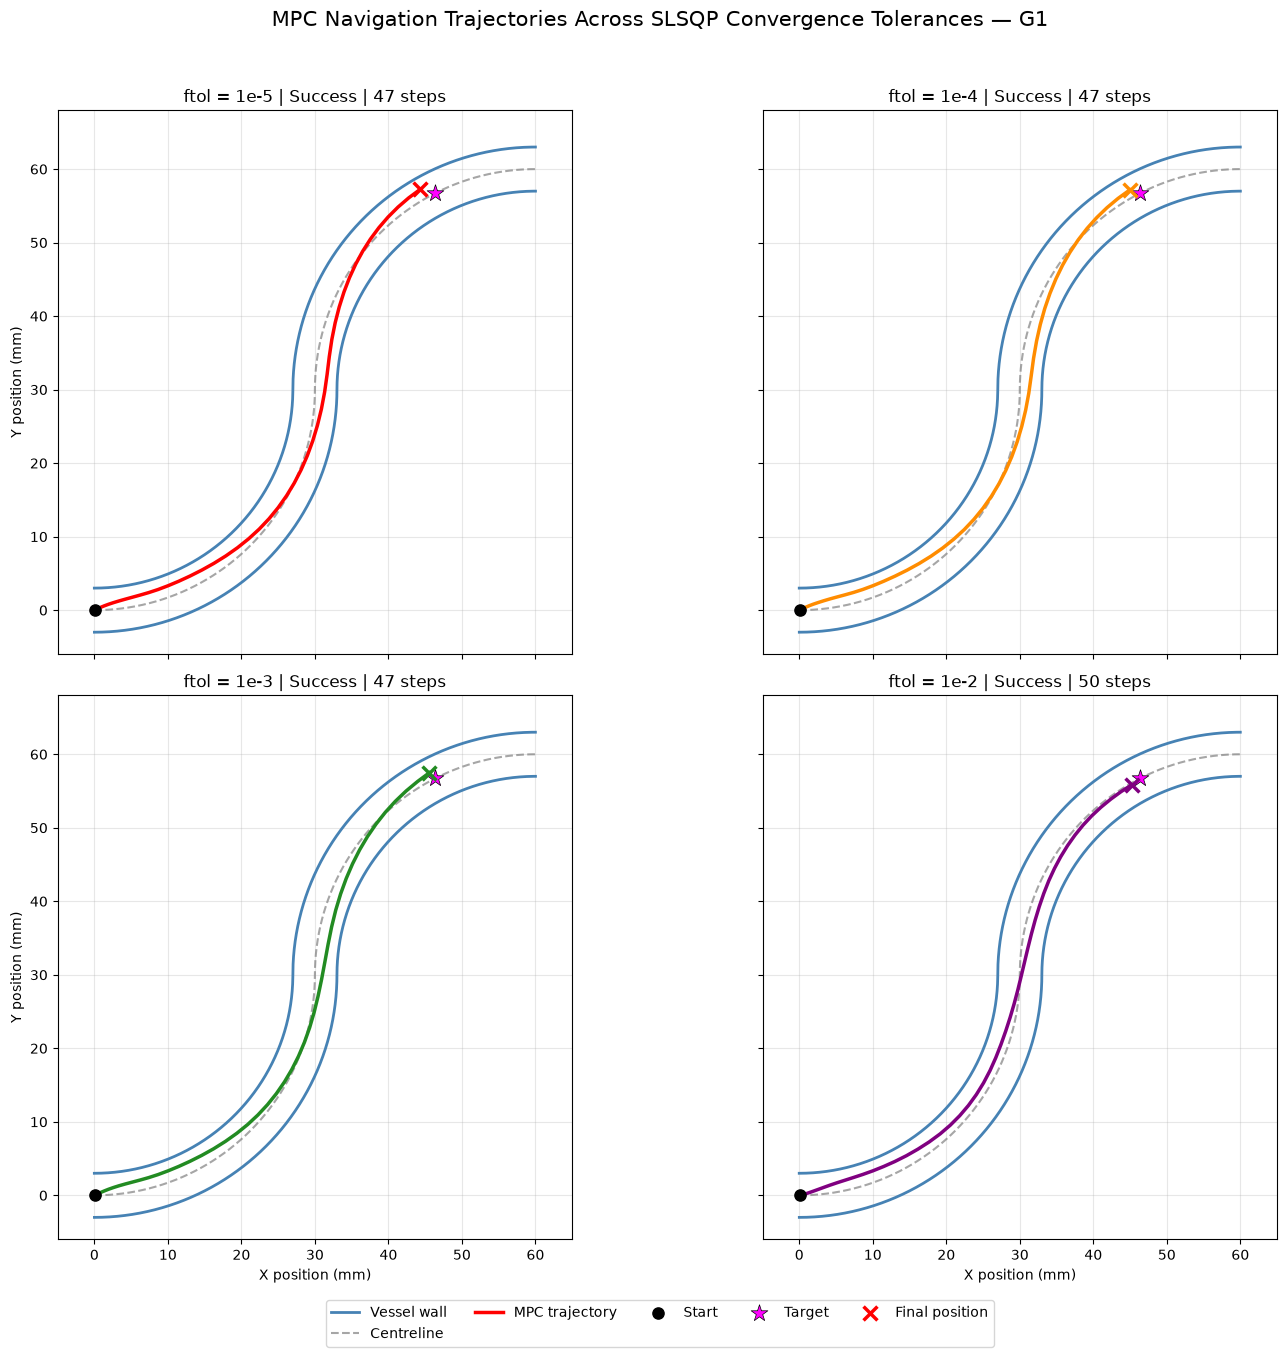

In [38]:

# ======================================================================
# MPC NAVIGATION TRAJECTORIES — FOUR SEPARATE SUBPLOTS
# ======================================================================

# Retrieve the four saved MPC experiment results.
tolerance_results = {
    "1e-5": horizon10_results,
    "1e-4": ftol4_results,
    "1e-3": ftol3_results,
    "1e-2": ftol2_results
}

# Convert vessel geometry from metres to millimetres.
centreline_mm = vessel.centreline * 1000.0
wall1_mm = vessel.wall1 * 1000.0
wall2_mm = vessel.wall2 * 1000.0
target_mm = vessel.target_position * 1000.0

# Assign a distinct colour to each tolerance.
trajectory_colors = {
    "1e-5": "red",
    "1e-4": "darkorange",
    "1e-3": "forestgreen",
    "1e-2": "purple"
}

# Create four large subplots arranged in two rows and two columns.
fig, axes = plt.subplots(
    2, 2,
    figsize=(15, 14),
    sharex=True,
    sharey=True
)

# Flatten the axes array so we can iterate through the four plots.
axes = axes.flatten()

# ======================================================================
# PLOT EACH MPC TRAJECTORY IN ITS OWN AXIS
# ======================================================================

for ax, (ftol_label, result) in zip(axes, tolerance_results.items()):

    # Extract the recorded physical states [x, y, vx, vy].
    states_trial = result["states"]

    # Extract catheter positions and convert to millimetres.
    positions_mm = states_trial[:, :2] * 1000.0

    # Plot the two vessel boundaries.
    ax.plot(
        wall1_mm[:, 0], wall1_mm[:, 1],
        color="steelblue", linewidth=2,
        label="Vessel wall"
    )

    ax.plot(
        wall2_mm[:, 0], wall2_mm[:, 1],
        color="steelblue", linewidth=2
    )

    # Plot the vessel centreline for reference.
    ax.plot(
        centreline_mm[:, 0], centreline_mm[:, 1],
        color="gray", linestyle="--",
        linewidth=1.5, alpha=0.7,
        label="Centreline"
    )

    # Plot the MPC-controlled catheter trajectory.
    ax.plot(
        positions_mm[:, 0], positions_mm[:, 1],
        color=trajectory_colors[ftol_label],
        linewidth=2.5,
        label="MPC trajectory"
    )

    # Mark the starting position.
    ax.scatter(
        positions_mm[0, 0], positions_mm[0, 1],
        color="black", marker="o", s=65,
        label="Start", zorder=5
    )

    # Mark the target.
    ax.scatter(
        target_mm[0], target_mm[1],
        color="magenta", marker="*",
        s=160, edgecolors="black",
        linewidths=0.5,
        label="Target", zorder=6
    )

    # Mark the final recorded catheter position.
    ax.scatter(
        positions_mm[-1, 0], positions_mm[-1, 1],
        color=trajectory_colors[ftol_label],
        marker="x", s=100,
        linewidths=2.5,
        label="Final position", zorder=6
    )

    # Display the tolerance and navigation outcome above each subplot.
    ax.set_title(
        f"ftol = {ftol_label} | {result['outcome'].capitalize()} "
        f"| {len(result['actions'])} steps",
        fontsize=12
    )

    # Preserve equal physical scaling for all vessel plots.
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.3)

    # Apply consistent axis limits for fair comparison.
    ax.set_xlim(-5, 65)
    ax.set_ylim(-6, 68)

# ======================================================================
# FORMAT THE COMPLETE FIGURE
# ======================================================================

# Label axes for each row and column.
for ax in axes[2:]:
    ax.set_xlabel("X position (mm)")

for ax in axes[::2]:
    ax.set_ylabel("Y position (mm)")

# Create one common legend instead of repeating it on all four plots.
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles, labels,
    loc="lower center",
    ncol=5,
    fontsize=10,
    bbox_to_anchor=(0.5, 0.02)
)

fig.suptitle(
    "MPC Navigation Trajectories Across SLSQP Convergence Tolerances — G1",
    fontsize=15
)

# Leave room for the overall title and common legend.
fig.tight_layout(rect=[0, 0.06, 1, 0.96])

plt.show()



### Provisional MPC Baseline and Short-Horizon Wall-Penalty Investigation

The configuration with `N=10` and `ftol=1e-3` is provisionally selected as the MPC baseline because it achieved successful G1 navigation in 47 steps while substantially reducing computational cost compared with stricter convergence tolerances. The faster `ftol=1e-2` configuration is retained as a potential alternative for future investigation.

Before finalising the baseline, one additional experiment will investigate whether **tripling the wall-avoidance cost weight from 10 to 30** enables successful navigation with a shorter prediction horizon (`N=5`). All other parameters will remain unchanged, allowing comparison with the original horizon-5 failure and the successful horizon-10 configuration.


In [39]:

# ======================================================================
# MPC SHORT-HORIZON TEST — TRIPLE WALL-AVOIDANCE WEIGHT
# ======================================================================

# Create a separate cost configuration for this experiment.
# Keep all existing cost weights unchanged except the wall penalty.
cost_config_wall30 = replace(
    cost_config,
    wall_weight=3.0 * cost_config.wall_weight
)

# Display the original and modified wall weights.
print(f"Original wall weight: {cost_config.wall_weight}")
print(f"Modified wall weight: {cost_config_wall30.wall_weight}")

# Create a new MPC controller using the shorter prediction horizon.
mpc_controller_wall30 = MPCController(
    vessel=vessel,
    env_config=env_config,
    cost_config=cost_config_wall30,
    horizon=5,
    maxiter=50,
    ftol=1e-5
)

# Reset the environment and controller for an independent G1 experiment.
observation, info = env.reset(seed=42)
mpc_controller_wall30.reset()

# Retain the same 50-step development cutoff.
max_test_steps = 50

# Record the initial catheter state and remaining target distance.
initial_state = env.state.copy()
initial_distance = vessel.distance_to_target(initial_state[:2])

# Store the trajectory and applied forces separately.
states_wall30 = [initial_state.copy()]
actions_wall30 = []
progress_wall30 = [0.0]

terminated = False
truncated = False

# Start measuring the total wall-clock runtime.
test_start_time = perf_counter()

# ======================================================================
# RUN CLOSED-LOOP MPC WITH N = 5 AND WALL WEIGHT = 30
# ======================================================================

for step in range(max_test_steps):

    # Optimise the control sequence using the modified wall penalty.
    action = mpc_controller_wall30(observation)

    # Apply the selected force using the existing RK45 environment.
    observation, reward, terminated, truncated, info = env.step(action)

    # Record the updated catheter state and the applied action.
    states_wall30.append(env.state.copy())
    actions_wall30.append(action.copy())

    # Calculate cumulative centreline progress in millimetres.
    current_distance = vessel.distance_to_target(env.state[:2])
    progress_mm = (initial_distance - current_distance) * 1000.0
    progress_wall30.append(progress_mm)

    # Print progress every 10 steps or when the episode ends.
    if (step + 1) % 10 == 0 or terminated or truncated:
        print(
            f"Step {step + 1:>3} | "
            f"Progress: {progress_mm:>8.3f} mm | "
            f"Solver converged: "
            f"{mpc_controller_wall30.optimisation_history[-1]['success']}"
        )

    # Stop if the episode ends through success, failure or truncation.
    if terminated or truncated:
        print(f"\nEpisode ended: {info['outcome']}")
        break

# Calculate the total wall-clock runtime.
total_runtime_wall30 = perf_counter() - test_start_time

# Convert recorded states, actions and progress to NumPy arrays.
states_wall30 = np.asarray(states_wall30)
actions_wall30 = np.asarray(actions_wall30)
progress_wall30 = np.asarray(progress_wall30)

# Retrieve the solver diagnostics from this experiment.
solver_history_wall30 = mpc_controller_wall30.optimisation_history

# Store the experiment results without overwriting previous results.
wall30_results = {
    "horizon": 5,
    "ftol": 1e-5,
    "wall_weight": cost_config_wall30.wall_weight,
    "states": states_wall30.copy(),
    "actions": actions_wall30.copy(),
    "progress_history": progress_wall30.copy(),
    "solver_history": [record.copy() for record in solver_history_wall30],
    "outcome": info["outcome"],
    "episode_finished": bool(terminated or truncated),
    "runtime": total_runtime_wall30
}

# ======================================================================
# DISPLAY EXPERIMENT SUMMARY
# ======================================================================

print("\nMPC SHORT-HORIZON WALL-PENALTY TEST")
print("-" * 50)
print(f"Prediction horizon: 5 steps")
print(f"Wall-avoidance weight: {cost_config_wall30.wall_weight}")
print(f"Steps completed: {len(actions_wall30)}")
print(f"Navigation progress: {progress_wall30[-1]:.3f} mm")
print(f"Environment outcome: {info['outcome']}")
print(f"Total computational runtime: {total_runtime_wall30:.2f} s")

# Report whether the run finished naturally or reached our test cutoff.
if not (terminated or truncated):
    print("\nDevelopment test stopped at 50 steps; episode unfinished.")

print("\nShort-horizon wall-penalty test: COMPLETED")


Original wall weight: 10.0
Modified wall weight: 30.0
Step  10 | Progress:    5.288 mm | Solver converged: True
Step  20 | Progress:   22.476 mm | Solver converged: True
Step  27 | Progress:   36.736 mm | Solver converged: True

Episode ended: side_wall_violation

MPC SHORT-HORIZON WALL-PENALTY TEST
--------------------------------------------------
Prediction horizon: 5 steps
Wall-avoidance weight: 30.0
Steps completed: 27
Navigation progress: 36.736 mm
Environment outcome: side_wall_violation
Total computational runtime: 44.59 s

Short-horizon wall-penalty test: COMPLETED


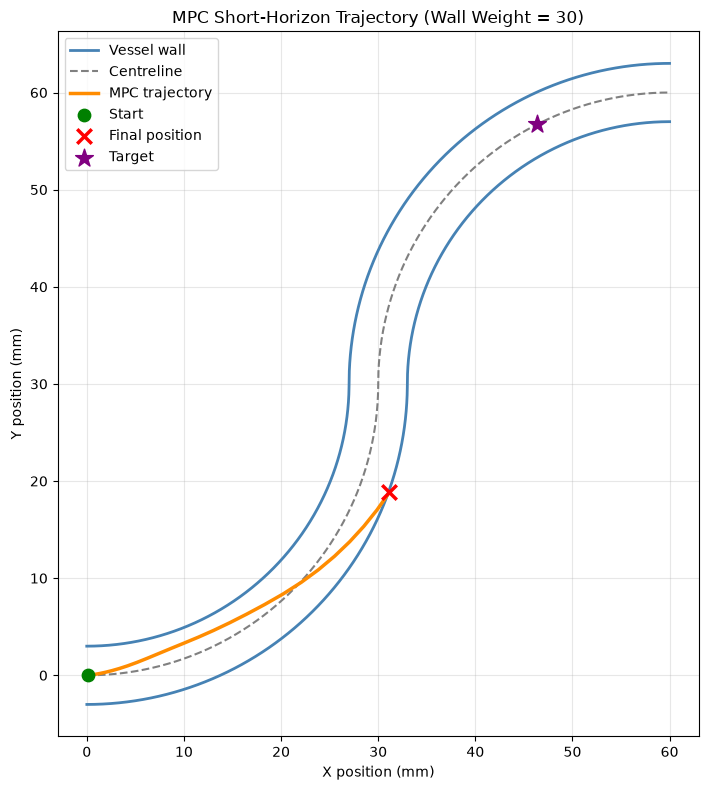

MPC TRAJECTORY SUMMARY — WALL WEIGHT = 30
------------------------------------------------
Outcome: side_wall_violation
Steps completed: 27
Prediction horizon: 5
Wall weight: 30.0
Runtime: 44.59 s
Final position (m): [0.03113995 0.01882108]


In [ ]:
# ======================================================================
# PLOT THE MPC TRAJECTORY FOR WALL WEIGHT = 30 ONLY
# ======================================================================

# Retrieve the recorded states from the wall-weight = 30 experiment.
states_wall30 = wall30_results["states"]

# Extract catheter positions and convert from metres to millimetres.
positions_wall30 = states_wall30[:, :2] * 1000.0

# Convert vessel geometry and target coordinates to millimetres.
wall1_mm = vessel.wall1 * 1000.0
wall2_mm = vessel.wall2 * 1000.0
centreline_mm = vessel.centreline * 1000.0
target_mm = vessel.target_position * 1000.0

# Extract the start and final catheter positions.
start_position = positions_wall30[0]
final_position = positions_wall30[-1]

# Create a large figure for readability.
fig, ax = plt.subplots(figsize=(9, 8))

# Plot the two vessel boundaries.
ax.plot(
    wall1_mm[:, 0], wall1_mm[:, 1],
    color="steelblue", linewidth=2,
    label="Vessel wall"
)
ax.plot(
    wall2_mm[:, 0], wall2_mm[:, 1],
    color="steelblue", linewidth=2
)

# Plot the vessel centreline.
ax.plot(
    centreline_mm[:, 0], centreline_mm[:, 1],
    color="gray", linestyle="--", linewidth=1.5,
    label="Centreline"
)

# Plot the catheter trajectory for the wall-weight = 30 experiment.
ax.plot(
    positions_wall30[:, 0], positions_wall30[:, 1],
    color="darkorange", linewidth=2.5,
    label="MPC trajectory"
)

# Mark the starting position.
ax.scatter(
    start_position[0], start_position[1],
    color="green", s=80, zorder=6,
    label="Start"
)

# Mark the final position.
ax.scatter(
    final_position[0], final_position[1],
    color="red", marker="x", s=110, linewidths=2.5,
    zorder=7, label="Final position"
)

# Mark the target position.
ax.scatter(
    target_mm[0], target_mm[1],
    color="purple", marker="*", s=180,
    zorder=7, label="Target"
)

# Format the axes and title.
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("X position (mm)")
ax.set_ylabel("Y position (mm)")
ax.set_title("MPC Short-Horizon Trajectory (Wall Weight = 30)")
ax.grid(alpha=0.3)
ax.legend(loc="upper left")

plt.tight_layout()
plt.show()

# Print a short summary for the plotted experiment.
print("MPC TRAJECTORY SUMMARY — WALL WEIGHT = 30")
print("-" * 48)
print(f"Outcome: {wall30_results['outcome']}")
print(f"Steps completed: {len(wall30_results['actions'])}")
print(f"Prediction horizon: {wall30_results['horizon']}")
print(f"Wall weight: {wall30_results['wall_weight']}")
print(f"Runtime: {wall30_results['runtime']:.2f} s")
print(f"Final position (m): {states_wall30[-1, :2]}")


### Short-Horizon MPC — Increased Wall Penalty

Tripling the wall-avoidance weight from 10 to 30 with `N=5` did not prevent a side-wall violation. The episode terminated after 27 steps, similar to the original configuration.

This suggests that **increasing the wall penalty alone was insufficient to compensate for the shorter prediction horizon** under baseline G1 conditions. Therefore, `N=10` and `ftol=1e-3` remain our provisional MPC baseline settings.



### Nominal G1 Baseline Evaluation — MPC

The provisional MPC controller (`N=10`, `ftol=1e-3`) is evaluated over five episodes with reproducible, randomly selected valid starting positions near the vessel entrance. The catheter begins each episode at rest, while the vessel geometry, physical parameters and controller settings remain unchanged.


In [47]:

# ======================================================================
# MPC BASELINE EVALUATION — FIVE NOMINAL G1 EPISODES
# ======================================================================


# ======================================================================
# 1. INITIALISE THE PROVISIONAL BASELINE CONTROLLER
# ======================================================================

# Use the selected MPC configuration and unchanged cost weights.
baseline_mpc_controller = MPCController(
    vessel=vessel,
    env_config=env_config,
    cost_config=cost_config,
    horizon=10,
    maxiter=50,
    ftol=1e-3
)

# Confirm that the nominal G1 environment has no process noise.
assert env.sigma_position == 0.0
assert env.sigma_velocity == 0.0

# ======================================================================
# 2. GENERATE FIVE REPRODUCIBLE, VALID STARTING POSITIONS
# ======================================================================

# Create a random generator with a fixed seed for reproducibility.
rng = np.random.default_rng(2026)

n_episodes = 5
initial_positions = []

# Randomly select valid positions near the vessel entrance.
for episode in range(n_episodes):

    # Select a centreline point within the first 20 sampled positions.
    centreline_index = int(rng.integers(5, 21))

    # Retrieve the selected centreline position and local vessel radius.
    centre_position = vessel.centreline[centreline_index]
    local_radius = vessel.local_radius[centreline_index]

    # Calculate the local unit tangent along the vessel centreline.
    tangent = (
        vessel.centreline[centreline_index + 1]
        - vessel.centreline[centreline_index - 1]
    )
    tangent = tangent / np.linalg.norm(tangent)

    # Rotate the tangent by 90 degrees to obtain the unit normal.
    normal = np.array([-tangent[1], tangent[0]])

    # Apply a random lateral offset within 25% of the local radius.
    lateral_offset = rng.uniform(-0.25, 0.25) * local_radius

    # Calculate the new initial catheter position [x, y].
    initial_position = centre_position + lateral_offset * normal

    # Confirm that the position lies inside the vessel.
    clearance, inside = vessel.wall_clearance(initial_position)

    assert inside, f"Episode {episode + 1}: invalid starting position."
    assert clearance > 0.0

    # Store the valid initial position.
    initial_positions.append(initial_position.copy())

# Convert the starting positions into a NumPy array.
initial_positions = np.asarray(initial_positions)

print("GENERATED G1 STARTING POSITIONS")
print("-" * 50)

for episode, position in enumerate(initial_positions, start=1):
    print(
        f"Episode {episode}: "
        f"x = {position[0] * 1000:.3f} mm, "
        f"y = {position[1] * 1000:.3f} mm"
    )

# ======================================================================
# 3. EVALUATE THE BASELINE MPC CONTROLLER
# ======================================================================

# Store results from all five independent evaluation episodes.
baseline_mpc_results = []

# Begin measuring the total wall-clock evaluation runtime.
evaluation_start_time = perf_counter()

for episode in range(n_episodes):

    # Reset warm-start information before each independent episode.
    baseline_mpc_controller.reset()

    # Start at the selected position with zero initial velocity.
    reset_options = {
        "initial_position": initial_positions[episode].copy(),
        "initial_velocity": [0.0, 0.0]
    }

    # Run the episode using our existing evaluation function.
    episode_result = evaluate_episode(
        env=env,
        controller=baseline_mpc_controller,
        seed=42 + episode,
        record_trajectory=True,
        reset_options=reset_options
    )

    # Save the complete result for this episode.
    baseline_mpc_results.append(episode_result)

    # Display the outcome and successful completion time.
    completion = episode_result["completion_time"]
    completion_text = (
        f"{completion:.3f} s" if completion is not None else "N/A"
    )

    print(
        f"Episode {episode + 1}/{n_episodes} | "
        f"Outcome: {episode_result['outcome']} | "
        f"Steps: {episode_result['steps']} | "
        f"Completion time: {completion_text}",
        flush=True
    )

# Calculate total wall-clock time across all five episodes.
baseline_mpc_runtime = perf_counter() - evaluation_start_time

# ======================================================================
# 4. SUMMARISE THE BASELINE EVALUATION
# ======================================================================

# Use the existing shared evaluation-summary function.
baseline_mpc_summary = summarise_evaluations(baseline_mpc_results)

print("\nMPC BASELINE EVALUATION — NOMINAL G1")
print("-" * 55)

print(f"Episodes evaluated: {baseline_mpc_summary['n_episodes']}")
print(f"Success rate: {baseline_mpc_summary['success_rate']:.1f}%")

print(
    f"Wall violation rate: "
    f"{baseline_mpc_summary['wall_violation_rate']:.1f}%"
)

# Mean completion time is undefined if no episode succeeds.
mean_completion = baseline_mpc_summary["mean_completion_time"]

if np.isnan(mean_completion):
    print("Mean successful completion time: N/A")
else:
    print(f"Mean successful completion time: {mean_completion:.3f} s")

print(f"Total evaluation runtime: {baseline_mpc_runtime:.2f} s")
print(f"Outcome counts: {baseline_mpc_summary['outcome_counts']}")

print("\nMPC nominal G1 baseline evaluation: COMPLETED")


GENERATED G1 STARTING POSITIONS
--------------------------------------------------
Episode 1: x = 1.687 mm, y = 0.258 mm
Episode 2: x = 0.662 mm, y = -0.042 mm
Episode 3: x = 0.571 mm, y = -0.212 mm
Episode 4: x = 0.930 mm, y = 0.450 mm
Episode 5: x = 1.535 mm, y = -0.445 mm
Episode 1/5 | Outcome: success | Steps: 46 | Completion time: 0.460 s
Episode 2/5 | Outcome: success | Steps: 46 | Completion time: 0.460 s
Episode 3/5 | Outcome: success | Steps: 46 | Completion time: 0.460 s
Episode 4/5 | Outcome: success | Steps: 47 | Completion time: 0.470 s
Episode 5/5 | Outcome: success | Steps: 46 | Completion time: 0.460 s

MPC BASELINE EVALUATION — NOMINAL G1
-------------------------------------------------------
Episodes evaluated: 5
Success rate: 100.0%
Wall violation rate: 0.0%
Mean successful completion time: 0.462 s
Total evaluation runtime: 1147.98 s
Outcome counts: {'success': 5}

MPC nominal G1 baseline evaluation: COMPLETED


In [51]:

# ======================================================================
# SAVE MPC BASELINE EVALUATION RESULTS TO CSV
# ======================================================================

# Calculate the mean runtime per episode for reference.
mean_episode_runtime = baseline_mpc_runtime / baseline_mpc_summary["n_episodes"]

# Create the output folder if it does not already exist.
results_dir = Path("experiments") / "results"
results_dir.mkdir(parents=True, exist_ok=True)

# Create a DataFrame containing our four primary evaluation metrics.
mpc_baseline_df = pd.DataFrame([{
    "Success rate (%)": baseline_mpc_summary["success_rate"],
    "Wall violation rate (%)": baseline_mpc_summary["wall_violation_rate"],
    "Mean completion time (s)": baseline_mpc_summary["mean_completion_time"],
    "Mean episode runtime (s)": mean_episode_runtime
}])

# Save the results as a CSV file without the Pandas row index.
csv_path = results_dir / "mpc_g1_baseline_results.csv"
mpc_baseline_df.to_csv(csv_path, index=False)

# Display the DataFrame and confirm the saved location.
display(mpc_baseline_df.round(3))
print(f"Results saved to: {csv_path.resolve()}")


,Success rate (%),Wall violation rate (%),Mean completion time (s),Mean episode runtime (s)
0,100.0,0.0,0.462,229.595


Results saved to: C:\Users\kizit\OneDrive - hull.ac.uk\Desktop\MSC_AI_FOR_ENG\DISSERTATION\Dissertation_Implementation_Repository\experiments\results\mpc_g1_baseline_results.csv



### MPC Baseline Evaluation — Summary

The selected MPC baseline (`N=10`, `ftol=1e-3`) was evaluated over five nominal G1 episodes with randomly varied valid starting positions and zero initial velocities.

The controller achieved a **100% success rate**, **0% wall violation rate**, and a **mean simulated completion time of 0.462 s**. The mean computational runtime was **229.596 s per episode**, highlighting the considerable computational cost of MPC despite successful navigation.

These results establish the **nominal G1 baseline performance** for subsequent comparison with SAC. The four prioritised evaluation metrics have been saved to `experiments/results/mpc_g1_baseline_results.csv`.